# I

## Big Data 101

### The 3 V's of Big Data

Three characteristics used to describe Big Data:

- **Volume** — the size of the data
- **Variety** — the different sources and formats of data
- **Velocity** — the speed at which data is generated and made available for processing

### Big Data concepts and terminology

| Concept | Definition | Role |
|---|---|---|
| **Clustered computing** | Pooling resources of multiple machines to complete jobs | *Resource pooling* |
| **Parallel computing** | A type of computation where many calculations are carried out simultaneously | *Style of computation* |
| **Distributed computing** | Involves nodes (networked computers) that run jobs in parallel | *Architecture* |
| **Batch processing** | Breaking data into smaller pieces and running each piece on an individual machine | *Timing — results in chunks* |
| **Real-time processing** | Demands that information is processed and made ready immediately | *Timing — results instantly* |

### Big Data processing systems

Two popular frameworks for Big Data processing:

#### Hadoop / MapReduce

- Open source and scalable framework
- Designed for **batch** data processing

#### Apache Spark

- Parallel framework for storing and processing Big Data across clustered computers
- Open source
- Suited for **both batch and real-time** data processing
- This is the framework we'll focus on for the rest of the course

### Features of Apache Spark framework

- Distributes data and computation across multiple computers, executing complex multi-stage applications such as machine learning
- Runs most computations **in memory**, giving much better performance for workloads like interactive data mining
- Performance figures to remember:
  - Up to **100× faster** when running in memory
  - Up to **10× faster** when running on disk (compared to Hadoop MapReduce)
- Written mainly in **Scala**, with APIs also available in Java, Python, R and SQL

A minimal PySpark entry point looks like this — we'll use `SparkSession` throughout the course:

```python
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[*]")          # local mode, using all cores
    .appName("intro-to-spark")
    .getOrCreate()
)

print(spark.version)
```

### Apache Spark components

Spark is a powerful alternative to Hadoop MapReduce, with rich features like machine learning, real-time stream processing and graph computations.

#### Spark Core

At the centre of the ecosystem — contains the basic functionality of Spark. Everything else is built on top of it.

#### Spark SQL

- Library for processing **structured and semi-structured** data
- Available in Python, Java and Scala
- One of the two components we'll focus on in this course

```python
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("sql-demo").getOrCreate()

df = spark.read.csv("people.csv", header=True, inferSchema=True)
df.createOrReplaceTempView("people")

spark.sql("""
    SELECT department, AVG(salary) AS avg_salary
    FROM people
    GROUP BY department
    ORDER BY avg_salary DESC
""").show()
```

#### MLlib

- Library of common **machine learning** algorithms
- The second component we'll focus on in this course

```python
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression

fifa = spark.read.csv("Fifa2018_dataset.csv", header=True, inferSchema=True)

assembler = VectorAssembler(
    inputCols=["Age", "Potential"],
    outputCol="features",
)
training = assembler.transform(fifa).select("features", "Overall")

lr = LinearRegression(featuresCol="features", labelCol="Overall")
model = lr.fit(training)
```

#### GraphX

Collection of algorithms and tools for manipulating graphs and performing parallel graph computations.

#### Spark Streaming

A scalable, high-throughput processing library for **real-time** data.

### Spark modes of deployment

Spark can be run in two modes:

#### Local mode

- Spark runs on a **single machine** (e.g. your laptop)
- Convenient for **testing, debugging and demonstration**

#### Cluster mode

- Spark runs on an actual **cluster** of machines
- Mainly used for **production** workloads

Important to remember: the typical development workflow is to **start on local mode and transition to cluster mode** — and crucially, **no code change is necessary** when making that transition. The same PySpark script runs in both environments; only the `master` configuration changes.

```python
# Local mode — single machine, all cores
spark_local = (
    SparkSession.builder
    .master("local[*]")
    .appName("dev-run")
    .getOrCreate()
)

# Cluster mode — point at the cluster manager instead
spark_cluster = (
    SparkSession.builder
    .master("spark://cluster-master:7077")   # or "yarn", "k8s://..."
    .appName("prod-run")
    .getOrCreate()
)
```

### Key takeaways / cheat sheet

| Concept | One-liner |
|---|---|
| Big Data | Data sets too complex for traditional data-processing software |
| 3 V's | **V**olume (size), **V**ariety (format), **V**elocity (speed) |
| Clustered computing | Pooling resources of multiple machines |
| Parallel computing | Many calculations happening simultaneously |
| Distributed computing | Networked nodes running jobs in parallel |
| Batch processing | Break data into pieces, process each on a machine |
| Real-time processing | Results must be ready immediately |
| Hadoop/MapReduce | Open-source, batch-only framework |
| Apache Spark | Open-source, batch + real-time, 10–100× faster than Hadoop |
| Spark languages | Scala (native), Java, Python, R, SQL |
| Spark Core | Base functionality — everything else sits on top |
| Spark SQL | Structured / semi-structured data (this course) |
| MLlib | Machine learning (this course) |
| GraphX | Graphs & parallel graph computation |
| Spark Streaming | Real-time, high-throughput streams |
| Local mode | Single machine — dev, test, debug |
| Cluster mode | Multi-machine — production; **same code as local** |

Key things to lock in:
- The **3 V's** — expect to be asked to define them
- Spark = **in-memory → 100× faster**, on disk → 10× faster
- Spark Core sits at the centre; SQL, MLlib, GraphX and Streaming are built on top
- Local ↔ cluster: **no code change needed**, just the `master` URL

In [5]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("spark-sesh").getOrCreate()
fifa = spark.read.csv("Fifa2018_dataset.csv", header=True, inferSchema=True)

assembler = VectorAssembler(
    inputCols=["Age", "Potential"],
    outputCol="features",
)
training = assembler.transform(fifa).select("features", "Overall")

lr = LinearRegression(featuresCol="features", labelCol="Overall")
model = lr.fit(training)

26/11/15 13:40:42 WARN Utils: Your hostname, DDG-1000 resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/15 13:40:42 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/15 13:40:43 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/11/15 13:40:52 WARN Instrumentation: [6803b08e] regParam is zero, which might cause numerical instability and overfitting.
26/11/15 13:40:53 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS


In [6]:
model

LinearRegressionModel: uid=LinearRegression_dca50ad082bc, numFeatures=2

## PySpark: Spark with Python


- Apache Spark background: fast, general-purpose framework for Big Data processing with high-level APIs in Scala, Java, Python and R
- Focus of this session: PySpark, Spark's Python flavour

### Overview of PySpark

- Apache Spark was originally written in Scala
- PySpark was developed to bring Python support to Spark
- The newest PySpark version offers computation power comparable to Scala — earlier versions lagged behind
- APIs feel familiar to anyone coming from Pandas and Scikit-learn, so the barrier to entry is low for beginners

### What is Spark shell?

- Spark ships with interactive shells for ad-hoc data analysis
- A Spark shell gives quick, convenient access to Spark's functionality — handy for rapid prototyping before pushing jobs onto a cluster
- Key distinguishing feature: unlike most shells, a Spark shell can interact with data distributed across disk or memory on many machines, with Spark handling the distribution automatically
- Three flavours are provided, one per supported language:
  - `spark-shell` — Scala
  - `pyspark` — Python
  - `sparkR` — R

### PySpark shell

- Python-based command line tool for developing interactive Spark applications in Python
- Acts as the bridge between Python and Spark's data structures
- Like the Scala shell, it supports connecting to a cluster
- This course works entirely inside the PySpark shell

### Understanding SparkContext

- An **entry point** is where control transfers from the operating system to the program — analogous to a key for a house: no key, no entry
- `SparkContext` is the entry point for interacting with underlying Spark functionality — without it, no PySpark job can run

```python
sc = spark.sparkContext
sc
# <SparkContext master=local[*] appName=PySparkShell>
```

### Inspecting SparkContext

Three important attributes worth knowing:

**Version** — reports the Spark version currently running:

```python
sc.version
# '3.5.0'
```

**Python version** — reports the Python version Spark is using:

```python
sc.pythonVer
# '3.12'
```

**Master** — the URL of the cluster, or the string `local` when running in local mode:

```python
sc.master
# 'local[*]'
```

Important to remember: `local` means `SparkContext` is acting as master on a local node, using all available threads on the host machine.

### Loading data in PySpark

Two main routes into `SparkContext` for raw data.

**1. `parallelize()`** — turns an in-memory Python collection into a distributed dataset (RDD):

```python
# Parallelize a list of integers
numbers = sc.parallelize([1, 2, 3, 4, 5])
numbers.collect()
# [1, 2, 3, 4, 5]
```

**2. `textFile()`** — loads a text file from disk into an RDD, one line per element:

```python
# Load a text file
lines = sc.textFile("test.txt")
lines.take(3)
```

### Quick summary / key takeaways

| Concept | Essentials |
|---|---|
| PySpark | Python API over Spark; Scala-level performance; Pandas-like feel |
| Spark shell | Interactive shell; three languages — `spark-shell`, `pyspark`, `sparkR` |
| Entry point | Required to run jobs; think "key to the house" |
| `SparkContext` | The entry point; exposed as `sc` in the PySpark shell |
| `sc.version` | Spark version |
| `sc.pythonVer` | Python version Spark is using |
| `sc.master` | Cluster URL or `local` |
| `sc.parallelize(list)` | Distribute a Python collection into an RDD |
| `sc.textFile(path)` | Load a text file into an RDD |

Cheat sheet reference: [DataCamp PySpark cheat sheet](https://www.datacamp.com/cheat-sheet/pyspark-cheat-sheet-spark-in-python)

In [7]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("pyspark-shell").getOrCreate()

sc = spark.sparkContext

26/11/15 13:40:54 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


In [8]:
# Print the version of SparkContext
print("The version of Spark Context in the PySpark shell is", sc.version)

# Print the Python version of SparkContext
print("The Python version of Spark Context in the PySpark shell is", sc.pythonVer)

# Print the master of SparkContext
print("The master of Spark Context in the PySpark shell is", sc.master)

The version of Spark Context in the PySpark shell is 3.5.9
The Python version of Spark Context in the PySpark shell is 3.12
The master of Spark Context in the PySpark shell is local[*]


In [9]:
# Create a Python list of numbers from 1 to 100 
numb = range(1, 1000)

# Load the list into Spark using Spark Context's parallelize method and assign it to a variable spark_data.
spark_data = sc.parallelize(numb)

In [10]:
spark_data

PythonRDD[34] at RDD at PythonRDD.scala:53

In [11]:
file_path = "README.md"

In [12]:
# Load a local file into PySpark shell
lines = sc.textFile(file_path)

In [13]:
lines.collect()

['[![buildstatus](https://travis-ci.org/holdenk/learning-spark-examples.svg?branch=master)](https://travis-ci.org/holdenk/learning-spark-examples)',
 'Examples for Learning Spark',
 '===============',
 'Examples for the Learning Spark book. These examples require a number of libraries and as such have long build files. We have also added a stand alone example with minimal dependencies and a small build file',
 'in the mini-complete-example directory.',
 '',
 '',
 'These examples have been updated to run against Spark 1.3 so they may',
 'be slightly different than the versions in your copy of "Learning Spark".',
 '',
 'Requirements',
 '==',
 '- JDK 1.7 or higher',
 '- Scala 2.10.3',
 '- scala-lang.org',
 '- Spark 1.3',
 '- Protobuf compiler',
 '- On debian you can install with sudo apt-get install protobuf-compiler',
 '- R & the CRAN package Imap are required for the ChapterSixExample',
 '- The Python examples require urllib3',
 '',
 'Python examples',
 '===',
 '',
 'From spark just run

## Use of Lambda function in python - filter()

- Big Data Fundamentals with PySpark
- Functional programming in Python → makes PySpark easier
- Review of `lambda`, `map`, `filter`

### Lambda — quick refresher

A lambda **is a function** — same species as a `def`, just written inline and nameless.

Same function, two ways of writing it:

```python
# regular def
def double(x):
    return x * 2

# lambda
double = lambda x: x * 2
```

Both return a function that doubles its input. Identical behaviour — the lambda just squeezes it onto one line and drops the `return` keyword.

**Side-by-side anatomy:**

| Piece | `def` version | `lambda` version |
|---|---|---|
| Keyword | `def` | `lambda` |
| Name | `double` (required) | none (optional — can be assigned) |
| Parameters | `(x)` — in parentheses | `x` — no parentheses |
| Body | indented block | single expression after `:` |
| Return | explicit `return` | implicit — expression value comes out |
| Number of lines | ≥ 2 | 1 |

Four pieces to `lambda x: x * 2`:

| Part | Role |
|---|---|
| `lambda` | marks it as anonymous |
| `x` | parameter (no parentheses) |
| `:` | separator |
| `x * 2` | body — **one expression**, auto-returned |

**Where lambdas actually turn up — two places:**

1. Passed straight to something that wants a function (`map`, `filter`, `sorted(..., key=...)`, Spark ops) → this is where they earn their keep
2. Assigned to a variable name (`double = lambda x: x * 2`) → works, but if it's getting a name, `def` would do the same job and shows up more sensibly in tracebacks

**Hard rule — body must be ONE expression:**

- ✗ no `return`
- ✗ no multi-line body
- ✗ no `if:` / `for:` / `while:` blocks
- ✓ expressions only (ternary `A if cond else B` is fine — it's an expression)

Any of the ✗ things needed → use `def`.

### Anonymous functions in Python

- Lambda functions are **anonymous functions** in Python
- Very powerful, and efficient with `map()`, `filter()`, and `def`
- Lambda functions create functions to be called later, similar to `def`
- Returns the function **without any name** (i.e. anonymous)
- Used to inline a function definition or defer execution of code

### Lambda function syntax

General form:

```python
lambda arguments: expression
```

Example:

```python
double = lambda x: x * 2
print(double(3))
# 6
```

- `x` → argument
- `x * 2` → expression, evaluated and returned
- Function has no name; function object is assigned to `double`
- Calling `double(3)` returns `6`

### `def` vs `lambda`

Cube of a number, both ways:

```python
def cube(x):
    return x ** 3

g = lambda x: x ** 3

print(g(10))
print(cube(10))
# 1000
# 1000
```

Identical output from both forms.

Two differences highlighted on the slide:

- **No `return` statement** for lambda — the expression is returned implicitly
- **Can put lambda function anywhere** — no need to bind it to a name, unlike `def`

### Lambda with `map()`

`map()` applies a function to all items in the input list.

General syntax:

```python
map(function, list)
```

Example — add 2 to every item:

```python
items = [1, 2, 3, 4]
list(map(lambda x: x + 2, items))
# [3, 4, 5, 6]
```

`2` added to each element of `[1, 2, 3, 4]` → `[3, 4, 5, 6]`.

### Lambda with `filter()`

`filter()` takes a function and a list, and returns a new list containing items for which the function evaluates as `True`.

General syntax:

```python
filter(function, list)
```

Example — keep only odd numbers:

```python
items = [1, 2, 3, 4]
list(filter(lambda x: (x%2 != 0), items))
# [1, 3]
```

Only `1` and `3` survive — the odd numbers from the input.

**nb — map vs filter:**

- `map` lambda is a **transformer** → return value *replaces* the item. Output same length as input.
- `filter` lambda is a **predicate** → return value should be truthy/falsy. Output ≤ input length.

### Why this matters for PySpark

Same pattern carries over to RDD transformations:

```python
rdd = sc.parallelize([1, 2, 3, 4])

rdd.map(lambda x: x + 2).collect()          # [3, 4, 5, 6]
rdd.filter(lambda x: (x%2 != 0)).collect()  # [1, 3]
```

Same mental model — just distributed.

### Key takeaways

| Concept | What it does | Shape |
|---|---|---|
| `lambda` | Anonymous, inline function | `lambda args: expression` |
| `map(f, lst)` | Apply `f` to every item | New list, same length |
| `filter(f, lst)` | Keep items where `f(item)` is `True` | New list, ≤ same length |

**Lambda — hold on to:**

- It's **just a function**, written inline & nameless
- Body is **one expression**, returned implicitly — no `return`, no blocks
- Best used **passed as an argument**; if it's getting a name → use `def` instead
- Need `if`, loops, or multi-line logic → `def`, not lambda
- `map` transforms, `filter` selects — both pair cleanly with lambdas, in plain Python and in PySpark

In [14]:
my_list = list(range(1,10))

In [15]:
# Print my_list in the console
print("Input list is", my_list)

# Square all numbers in my_list
squared_list_lambda = list(map(lambda x: x ** 2, my_list))

# Print the result of the map function
print("The squared numbers are", squared_list_lambda)

Input list is [1, 2, 3, 4, 5, 6, 7, 8, 9]
The squared numbers are [1, 4, 9, 16, 25, 36, 49, 64, 81]


In [16]:
my_list2 = [10, 21, 31, 40, 51, 60, 72, 80, 93, 101]

In [17]:
# Print my_list2 in the console
print("Input list is:", my_list2)

# Filter numbers divisible by 10
filtered_list = list(filter(lambda x: (x%10 == 0), my_list2))

# Print the numbers divisible by 10
print("Numbers divisible by 10 are:", filtered_list)

Input list is: [10, 21, 31, 40, 51, 60, 72, 80, 93, 101]
Numbers divisible by 10 are: [10, 40, 60, 80]


# II

## Introduction to PySpark RDD

### What is RDD?

- RDD stands for **Resilient Distributed Datasets**
- A collection of data distributed across the cluster
- The fundamental, backbone data type in PySpark
- When Spark starts processing data, it divides the data into **partitions** and distributes those partitions across cluster nodes — each node holds only a slice of the full dataset

### Decomposing RDDs

The name itself captures three defining properties:

- **Resilient** — the ability to withstand failures and recompute missing or damaged partitions
- **Distributed** — spanning jobs across multiple nodes in the cluster for efficient computation
- **Datasets** — a collection of partitioned data, e.g. arrays, tables, tuples or other objects

### Creating RDDs

Three different methods exist for creating an RDD:

- **Parallelising an existing collection** — take an existing collection of objects (a list, an array, a set) and pass it to `SparkContext`'s `parallelize` method. This is the simplest method.
- **Loading from external datasets** — load data from files in HDFS, objects in Amazon S3 buckets, or lines in a text file stored locally, and pass it to `SparkContext`'s `textFile` method. This is the more common approach in practice.
- **From existing RDDs** — RDDs can be derived from other RDDs (covered in the next video)

### Parallelized collections

RDDs are created from a list or set using `SparkContext`'s `parallelize` method.

```python
# Example 1: RDD from a Python list of numbers
numRDD = sc.parallelize([1, 2, 3, 4])
type(numRDD)
# <class 'pyspark.rdd.RDD'>

# Example 2: RDD from a string
helloRDD = sc.parallelize("hello world")
type(helloRDD)
# <class 'pyspark.rdd.RDD'>
```

The object created can be confirmed as an RDD using Python's built-in `type` method.

### From external datasets

By far the most common method in real PySpark work. Uses `SparkContext`'s `textFile` method.

```python
# RDD created from a local text file
fileRDD = sc.textFile("README.md")
type(fileRDD)
# <class 'pyspark.rdd.RDD'>
```

As with the parallelize approach, `type` confirms the result is an RDD.

### Understanding Partitioning in PySpark

Data partitioning is central to Spark — understanding how Spark handles partitions is what allows parallelism to be controlled.

- A **partition** is a division of a large dataset, with each part stored in multiple locations across the cluster
- By default, Spark partitions the data at the time of RDD creation, based on factors such as available resources and the external datasets involved
- This default behaviour can be overridden by passing a second argument, `minPartitions`, which defines the minimum number of partitions to be created

```python
# Example 1: parallelize with 6 partitions
numRDD = sc.parallelize([1, 2, 3, 4, 5, 6, 7, 8, 9, 10], minPartitions=6)

# Example 2: textFile with 6 partitions
fileRDD = sc.textFile("README.md", minPartitions=6)

# Check how many partitions an RDD has
numRDD.getNumPartitions()
# 6
fileRDD.getNumPartitions()
# 6
```

The number of partitions in any RDD can always be checked using `getNumPartitions()`.

### Key takeaways

- **RDD** = Resilient + Distributed + Datasets — Spark's foundational data abstraction
- Three creation routes: `parallelize()` on a collection, `textFile()` from external storage, or transformation of an existing RDD
- Use `type(rdd)` to confirm an object is an RDD
- Partitioning controls parallelism; override Spark's default with the `minPartitions` argument
- Inspect partition count with `getNumPartitions()`

**Cheat sheet**

| Task | Method |
|---|---|
| Create RDD from a list/set | `sc.parallelize(collection)` |
| Create RDD from a text file | `sc.textFile("path")` |
| Set minimum partitions | pass `minPartitions=n` as second arg |
| Count partitions | `rdd.getNumPartitions()` |
| Verify RDD type | `type(rdd)` |

In [18]:
# Create an RDD from a list of words
RDD = sc.parallelize(["Spark", "is", "a", "framework", "for", "Big Data processing"])

# Print out the type of the created object
print("The type of RDD is", type(RDD))

The type of RDD is <class 'pyspark.rdd.RDD'>


In [19]:
file_path = "README.md"

In [20]:
# Print the file_path
print("The file_path is", file_path)

# Create a fileRDD from file_path
fileRDD = sc.textFile(file_path)

# Check the type of fileRDD
print("The file type of fileRDD is", type(fileRDD))

The file_path is README.md
The file type of fileRDD is <class 'pyspark.rdd.RDD'>


In [21]:
# Check the number of partitions in fileRDD
print("Number of partitions in fileRDD is", fileRDD.getNumPartitions())

# Create a fileRDD_part from file_path with 5 partitions
fileRDD_part = sc.textFile(file_path, minPartitions = 5)

# Check the number of partitions in fileRDD_part
print("Number of partitions in fileRDD_part is", fileRDD_part.getNumPartitions())

Number of partitions in fileRDD is 2
Number of partitions in fileRDD_part is 5


## RDD operations in PySpark

### Overview of PySpark operations

RDDs support two kinds of operations:

- **Transformations** — operations on RDDs that return a *new* RDD
- **Actions** — operations that perform some computation on the RDD and return a value

### RDD Transformations

The defining feature behind fault tolerance and efficient resource use is **lazy evaluation**.

- Spark builds a graph from every operation applied to an RDD
- Execution of that graph only begins once an **action** is performed
- No computation happens at the transformation step itself — just graph construction

Transformations covered in this lecture: `map`, `filter`, `flatMap`, `union`.

### map() Transformation

Takes in a function and applies it to **each element** of the RDD. The function's output becomes the new value of each element in the resulting RDD.

- Input: `[1, 2, 3, 4]`
- Function: square each element
- Output: `[1, 4, 9, 16]`

```python
# Create the RDD
RDD = sc.parallelize([1, 2, 3, 4])

# Apply map to square each element
RDD_map = RDD.map(lambda x: x * x)
```

### filter() Transformation

Takes in a function and returns an RDD containing only the elements that pass the condition (predicate).

- Input: `[1, 2, 3, 4]`
- Condition: `x > 2`
- Output: `[3, 4]`

```python
RDD = sc.parallelize([1, 2, 3, 4])

# Keep only elements greater than 2
RDD_filter = RDD.filter(lambda x: x > 2)
```

### flatMap() Transformation

Similar to `map`, but returns **multiple values** for each element in the source RDD — the results are flattened into a single RDD.

- Input: `["hello world", "how are you"]` → 2 elements
- Function: `split()` each string
- Output: `["hello", "world", "how", "are", "you"]` → 5 elements

Important point: even though the input RDD has 2 elements, the output RDD contains 5.

```python
RDD = sc.parallelize(["hello world", "how are you"])

# Split each string into words, flattened into a single RDD
RDD_flatmap = RDD.flatMap(lambda x: x.split(" "))
```

### union() Transformation

Returns the union of one RDD with another RDD — combines the two into a single RDD containing all elements from both.

Typical pattern: filter an input RDD twice to produce two separate RDDs, then merge them.

```python
# Load log file as an RDD
inputRDD = sc.textFile("logs.txt")

# Two filters producing two sub-RDDs
errorsRDD   = inputRDD.filter(lambda line: "error"   in line.split())
warningsRDD = inputRDD.filter(lambda line: "warning" in line.split())

# Combine them
combinedRDD = errorsRDD.union(warningsRDD)
```

### RDD Actions

Operations applied to RDDs that return a value after running the computation — this is what finally triggers the lazy graph to execute.

Four basic actions in this lesson: `collect`, `take`, `first`, `count`.

### collect() and take() Actions

- `collect()` — returns the *complete* list of elements from the RDD (brings all data back to the driver, so use with care on large RDDs)
- `take(N)` — returns the first `N` elements from the RDD

```python
# Using the earlier RDD_map (squared values of 1..4)
RDD_map.collect()
# [1, 4, 9, 16]

RDD_map.take(2)
# [1, 4]
```

### first() and count() Actions

- `first()` — returns the first element in an RDD (equivalent to `take(1)` but returns a single value rather than a list)
- `count()` — returns the total number of elements/rows in the RDD

```python
RDD_map.first()
# 1

RDD_flatmap.count()
# 5
```

### Key takeaways

- RDD operations come in two flavours: **Transformations** (lazy, return a new RDD) and **Actions** (eager, return a value)
- Lazy evaluation means no computation happens until an action is called — Spark just builds a graph
- `map` is one-to-one, `flatMap` is one-to-many (flattened), `filter` keeps elements matching a predicate, `union` concatenates two RDDs
- `collect()` pulls everything to the driver — risky on big data; prefer `take(N)` for a quick peek
- `first()` is a handy shorthand for `take(1)[0]`, and `count()` gives the element total

**Cheat sheet**

| Operation | Type | What it does |
|---|---|---|
| `map(f)` | Transformation | Apply `f` to every element (1-to-1) |
| `filter(f)` | Transformation | Keep elements where `f(x)` is `True` |
| `flatMap(f)` | Transformation | Apply `f`, flatten results (1-to-many) |
| `union(other)` | Transformation | Combine two RDDs |
| `collect()` | Action | Return all elements as a list |
| `take(N)` | Action | Return first `N` elements |
| `first()` | Action | Return the first element |
| `count()` | Action | Return the number of elements |

In [22]:
numbRDD = sc.parallelize(list(range(1,10)))

In [23]:
# Create map() transformation to cube numbers
cubedRDD = numbRDD.map(lambda x: x ** 3)

# Collect the results
numbers_all = cubedRDD.collect()

# Print the numbers from numbers_all
for numb in numbers_all:
	print(numb)

1
8
27
64
125
216
343
512
729


In [24]:
fileRDD = sc.textFile(file_path)

In [25]:
# Filter the fileRDD to select lines with Spark keyword
fileRDD_filter = fileRDD.filter(lambda line: 'Spark' in line)

# How many lines are there in fileRDD?
print("The total number of lines with the keyword Spark is", fileRDD_filter.count())

# Print the first four lines of fileRDD
for line in fileRDD_filter.take(4):
  print(line)

The total number of lines with the keyword Spark is 7
Examples for Learning Spark
Examples for the Learning Spark book. These examples require a number of libraries and as such have long build files. We have also added a stand alone example with minimal dependencies and a small build file
These examples have been updated to run against Spark 1.3 so they may
be slightly different than the versions in your copy of "Learning Spark".


## Working with Pair RDDs in PySpark

- Follows on from basic RDD operations
- Focus: RDDs of **key/value pairs** — a common structure for many Spark operations

### Introduction to pair RDDs in PySpark

- Most real-world datasets are naturally key/value pairs
- Example: a FIFA dataset where the **nationality** is the key and the **list of players** is the value, or **club** as key with **player names** as values
- Typical pattern: each row is a key that maps to one or more values
- PySpark provides a special data structure — **pair RDDs** — for this kind of dataset
- Key = the identifier; Value = the data

### Creating pair RDDs

Two most common ways:

- From a list of key/value tuples
- From a regular RDD

Either way, the first step is getting the data into key/value form.

```python
# Method 1: pair RDD directly from a list of (key, value) tuples
# Using FIFA data: (player name, age)
player_tuples = [
    ("Cristiano Ronaldo", 32),
    ("L. Messi", 30),
    ("Neymar", 25),
    ("L. Suárez", 30),
]
pairRDD_tuple = sc.parallelize(player_tuples)
```

```python
# Method 2: pair RDD from a regular RDD
# Each string holds "name,age" — split and emit a tuple
raw = ["Cristiano Ronaldo,32", "L. Messi,30", "Neymar,25", "L. Suárez,30"]
regularRDD = sc.parallelize(raw)

pairRDD_rdd = regularRDD.map(lambda s: (s.split(",")[0], int(s.split(",")[1])))
```

### Transformations on pair RDDs

- Pair RDDs are still RDDs, so every regular transformation still applies
- Because the elements are tuples, the function passed in must operate on **key/value pairs**
- Special transformations exist for this kind: `reduceByKey`, `groupByKey`, `sortByKey`, `join`

### reduceByKey() transformation

- The most popular pair RDD transformation
- Combines values with the same key using a supplied function
- Runs in parallel — one operation per key in the dataset
- Because datasets can contain very large numbers of keys, `reduceByKey` is **not** an action; it returns a new RDD of `(key, reduced_value)`

Example: total goals scored per player (summing across matches).

```python
# (player, goals in match) — several matches per player
goals = [
    ("Ronaldo", 2), ("Messi", 1), ("Ronaldo", 1),
    ("Neymar", 3), ("Messi", 2), ("Neymar", 1),
]
goalsRDD = sc.parallelize(goals)

totalGoalsRDD = goalsRDD.reduceByKey(lambda a, b: a + b)
totalGoalsRDD.collect()
# [('Ronaldo', 3), ('Messi', 3), ('Neymar', 4)]
```

### sortByKey() transformation

- Returns an RDD sorted by **key** in ascending (default) or descending order
- Works as long as an ordering is defined on the key

To sort the previous result by *number of goals* rather than by player name, swap key and value first using `map`, then call `sortByKey`.

```python
# Swap (player, goals) -> (goals, player), then sort by goals (desc)
sortedByGoals = totalGoalsRDD.map(lambda x: (x[1], x[0])).sortByKey(ascending=False)
sortedByGoals.collect()
# [(4, 'Neymar'), (3, 'Ronaldo'), (3, 'Messi')]
```

### groupByKey() transformation

- Groups all values with the same key into a single iterable
- Common use case: collecting every item that belongs to a given key — e.g. all players for a given nationality

```python
# (nationality, player)
players = [
    ("Portugal",  "Cristiano Ronaldo"),
    ("Argentina", "L. Messi"),
    ("Brazil",    "Neymar"),
    ("Uruguay",   "L. Suárez"),
    ("Brazil",    "Thiago Silva"),
    ("Argentina", "Sergio Agüero"),
]
playersRDD = sc.parallelize(players)

groupedRDD = playersRDD.groupByKey()
for nation, names in groupedRDD.collect():
    print(nation, list(names))
# Portugal  ['Cristiano Ronaldo']
# Argentina ['L. Messi', 'Sergio Agüero']
# Brazil    ['Neymar', 'Thiago Silva']
# Uruguay   ['L. Suárez']
```

Important point: `groupByKey` can be expensive for large datasets — `reduceByKey` is usually preferable when aggregating, because it combines locally before the shuffle.

### join() transformation

- Joins two pair RDDs on their key
- Result: elements with the same key are merged, producing `(key, (value_from_RDD1, value_from_RDD2))`

Example using FIFA data — RDD1 holds player ages, RDD2 holds weekly wages, both keyed by player name.

```python
RDD1 = sc.parallelize([
    ("Cristiano Ronaldo", 32),
    ("L. Messi", 30),
    ("Neymar", 25),
])

RDD2 = sc.parallelize([
    ("Cristiano Ronaldo", "€565K"),
    ("L. Messi", "€565K"),
    ("Neymar", "€280K"),
])

joinedRDD = RDD1.join(RDD2)
joinedRDD.collect()
# [('Cristiano Ronaldo', (32, '€565K')),
#  ('L. Messi',          (30, '€565K')),
#  ('Neymar',            (25, '€280K'))]
```

### Key takeaways

- Pair RDDs store `(key, value)` tuples and unlock a family of key-aware transformations
- Build them from a list of tuples with `parallelize`, or from a regular RDD using `map` to emit tuples
- `reduceByKey` aggregates values per key — efficient because it combines locally before shuffling
- `sortByKey` sorts by key; to sort by value, `map`-swap first then `sortByKey`
- `groupByKey` bundles all values for each key into an iterable — convenient but costly on big data
- `join` merges two pair RDDs on their shared key into `(key, (v1, v2))`

**Cheat sheet**

| Operation | Input | Output | Purpose |
|---|---|---|---|
| `parallelize([(k, v), ...])` | list of tuples | pair RDD | Create pair RDD directly |
| `rdd.map(lambda x: (k, v))` | regular RDD | pair RDD | Convert regular RDD to pair RDD |
| `reduceByKey(f)` | pair RDD | pair RDD | Combine values with same key using `f` |
| `sortByKey(ascending=True)` | pair RDD | pair RDD | Sort by key |
| `groupByKey()` | pair RDD | `(k, iterable)` | Group all values per key |
| `rdd1.join(rdd2)` | two pair RDDs | `(k, (v1, v2))` | Inner join on key |

In [26]:
# Create PairRDD Rdd with key value pairs
Rdd = sc.parallelize([(1,2),(3,4),(3,6),(4,5)])

# Apply reduceByKey() operation on Rdd
Rdd_Reduced = Rdd.reduceByKey(lambda x, y: x + y)

# Iterate over the result and print the output
for num in Rdd_Reduced.collect(): 
  print("Key {} has {} Counts".format(num[0], num[1]))

Key 1 has 2 Counts
Key 3 has 10 Counts
Key 4 has 5 Counts


## More actions

- Builds on advanced RDD transformations for key/value datasets
- Focus: advanced RDD **actions**, including some only available on pair RDDs

### reduce() action

- Takes in a function that operates on **two elements** of the same type and returns a new element of the same type
- The function must be **commutative** and **associative** so it can be computed correctly in parallel
- Classic example: `+`, which sums the whole RDD into a single value

```python
# Sum all elements of an RDD
RDD = sc.parallelize([1, 3, 4, 6])

total = RDD.reduce(lambda x, y: x + y)
print(total)
# 14
```

### saveAsTextFile() action

- Running `collect()` on huge RDDs is generally a bad idea — the whole dataset is pulled to the driver
- Common alternative: write the data out to distributed storage such as HDFS or Amazon S3
- `saveAsTextFile` writes an RDD to a directory as a text file
- By default, **each partition becomes a separate file** inside that directory

```python
# Save RDD with one file per partition
RDD.saveAsTextFile("file:///tmp/rdd_output")
```

To collapse all partitions into a **single file**, pipe the RDD through `coalesce(1)` first:

```python
# Reduce to a single partition, then save as one file
RDD.coalesce(1).saveAsTextFile("file:///tmp/rdd_output_single")
```

### Action Operations on pair RDDs

- All regular RDD actions still work on pair RDDs
- Pair RDDs also gain **extra actions** that exploit the key/value nature of the data
- Two covered here: `countByKey` and `collectAsMap`

### countByKey() action

- Only available on RDDs of type `(Key, Value)`
- Counts the number of elements for each key
- Returns a **dictionary** mapping key → count

```python
# Pair RDD: (character, line) tuples
rdd = sc.parallelize([("a", 1), ("b", 1), ("a", 1)])

for k, v in rdd.countByKey().items():
    print(k, v)
# a 2
# b 1
```

Important point: `countByKey` loads the result dictionary into driver memory — use it only when the dataset of distinct keys is small enough to fit.

### collectAsMap() action

- Returns the key/value pairs of the RDD to the driver as a **dictionary**
- Handy for downstream analysis where the data needs to be looked up by key

```python
pairRDD = sc.parallelize([(1, 2), (3, 4)])

result = pairRDD.collectAsMap()
print(result)
# {1: 2, 3: 4}
```

Same memory caveat as `countByKey`: only safe when the full result comfortably fits in memory, since every pair is pulled back to the driver.

### Key takeaways

- `reduce(f)` collapses an RDD to a single value — `f` must be commutative and associative
- `saveAsTextFile(path)` writes RDDs out to distributed storage, one file per partition by default; `coalesce(1)` first for a single output file
- `countByKey()` returns `{key: count}` — pair-RDD only
- `collectAsMap()` returns the whole pair RDD as a Python dict
- Both pair-RDD actions bring data back to the driver — only use them when the result is small

**Cheat sheet**

| Action | Available on | Returns | Notes |
|---|---|---|---|
| `reduce(f)` | any RDD | single value | `f` must be commutative & associative |
| `saveAsTextFile(path)` | any RDD | — (writes files) | 1 file per partition; use `coalesce(1)` for a single file |
| `countByKey()` | pair RDD | `dict` {key: count} | Result must fit in driver memory |
| `collectAsMap()` | pair RDD | `dict` {key: value} | Result must fit in driver memory |

In [27]:
Rdd = sc.parallelize([(1,2),(3,4),(3,6),(4,5)])

In [28]:
# Count the unique keys
total = Rdd.countByKey()

# What is the type of total?
print("The type of total is", type(total))

# Iterate over the total and print the output
for k, v in total.items(): 
  print("key", k, "has", v, "counts")

The type of total is <class 'collections.defaultdict'>
key 1 has 1 counts
key 3 has 2 counts
key 4 has 1 counts


In [29]:
file_path = "Complete_Shakespeare.txt"

In [30]:
# Create a RDD called `baseRDD` that reads lines from `file_path`.
baseRDD = sc.textFile(file_path)

# Transform the `baseRDD` into a long list of words and create a new `splitRDD`.
splitRDD = baseRDD.flatMap(lambda x: x.split())

# Count the total number words in `splitRDD`
print("Total number of words in splitRDD:", splitRDD.count())

Total number of words in splitRDD: 128576


In [31]:
stop_words = ['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', 'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', 'her', 'hers', 'herself', 'it', 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this', 'that', 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for', 'with', 'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above', 'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then', 'once', 'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 'some', 'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', 'too', 'very', 'can', 'will', 'just', 'don', 'should', 'now', 'project', 'gutenberg', 'ebook', 'ebooks', 'tm', 'copyright', 'license', 'electronic', 'work', 'works', 'distributed', 'foundation', 'archive', 'literary', 'gutenberg-tm', 'www', 'http', 'https', 'org', 'net', 'com', 'utf', 'ascii', 'txt', 'etext', 'etexts', 'release', 'produced', 'online', 'proofreading', 'team', 'pg', 'thou', 'thee', 'thy', 'thine', 'thyself', 'ye', 'hath', 'doth', 'hast', 'dost', 'art', 'wilt', 'shalt', 'canst', 'wouldst', 'shouldst', 'couldst', 'mayst', 'mightst', 'tis', 'twas', 'ere', 'oer', 'neer', 'unto', 'upon', 'wherefore', 'hence', 'thence', 'whence', 'hither', 'thither', 'whither', 'aye', 'nay', 'o', 'oh', 'lo', 'alas', 'sirrah', 'prithee', 'marry', 'quoth', 'shall', 'would', 'could', 'might', 'must', 'may', 'yet', 'thus', 'therefore', 'though', 'although', 'whose', 'whomsoever', 'whosoever', 'whatsoever', 'said', 'say', 'says', 'one', 'two', 'first', 'second', 'also', 'well', 'even', 'still', 'back', 'way', 'make', 'made', 'like', 'come', 'came', 'go', 'went', 'gone', 'see', 'saw', 'seen', 'know', 'knew', 'known', 'take', 'took', 'taken', 'give', 'gave', 'given', 'let', 'us', 'chapter', 'act', 'scene', 'enter', 'exit', 'exeunt']

In [32]:
# Filter splitRDD to remove stop words from the stop_words curated list
splitRDD_no_stop = splitRDD.filter(lambda x: x.lower() not in stop_words)

# Create a pair RDD tuple containing the word (using the w iterator) and the number 1 from each word element in splitRDD.
splitRDD_no_stop_words = splitRDD_no_stop.map(lambda w: (w, 1))

# Get the count of the number of occurrences of each word (word frequency) in the pair RDD. Use a transformation which operates on key, value (k,v) pairs. Think carefully about which function to use here.
resultRDD = splitRDD_no_stop_words.reduceByKey(lambda x, y: x + y)

In [33]:
# Display the first 10 words and their frequencies from the input RDD
for word in resultRDD.take(10):
	print(word)

# Swap the keys and values from the input RDD
resultRDD_swap = resultRDD.map(lambda x: (x[1], x[0]))

# Sort the keys in descending order
resultRDD_swap_sort = resultRDD_swap.sortByKey(ascending=False)

# Show the top 10 most frequent words and their frequencies from the sorted RDD
for word in resultRDD_swap_sort.take(10):
	print("{},{}". format(word[1], word[0]))

('Complete', 3)
('Shakespeare', 12)
('use', 38)
('anyone', 1)
('cost', 8)
('almost', 25)
('restrictions', 1)
('re-use', 1)
('Please', 8)
('file.', 1)
good,295
love,273
th',254
I'll,216
CLEOPATRA.,205
SYRACUSE.,205
ANTIPHOLUS,204
sir,,202
ANTONY.,202
ROSALIND.,201


## Introduction to PySpark DataFrames


- Builds on the previous chapter about RDDs (Spark's core data abstraction)
- Focus of this chapter: **PySpark SQL** — Spark's high-level API for structured data

### What are PySpark DataFrames?

- PySpark SQL is a Spark library for **structured data**
- Unlike the RDD API, PySpark SQL knows about the **structure** of the data *and* the computation being performed — enabling optimisations
- Its core programming abstraction is the **DataFrame**
- A DataFrame is an **immutable distributed collection of data with named columns** — conceptually similar to a table in SQL
- Designed to process:
  - Large collections of structured data (e.g. relational databases)
  - Semi-structured data such as JSON (JavaScript Object Notation)
- Available in multiple languages: Python, R, Scala, Java
- Two querying styles:
  - **SQL syntax** — e.g. `SELECT * FROM table`
  - **Expression/DSL method** — e.g. `df.select(...)`

### SparkSession — Entry point for DataFrame API

- `SparkContext` is the entry point for creating RDDs
- `SparkSession` is the equivalent entry point for the DataFrame API
- A SparkSession can be used to:
  - Create DataFrames
  - Register DataFrames as tables
  - Execute SQL over those tables
  - Cache tables, etc.
- Exposed in the PySpark shell as the variable `spark` (just as SparkContext is exposed as `sc`)

```python
# In the PySpark shell these are already defined, but outside the shell:
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("intro-to-df").getOrCreate()
```

### Creating DataFrames in PySpark

Two main routes:

- From an **existing RDD**, using `SparkSession.createDataFrame()`
- From an **external data source** (CSV, JSON, TXT, …), using `SparkSession.read`

Before the specifics — a note on **schema**:

- Schema = the structure of the data in a DataFrame
- Helps Spark **optimise queries** more efficiently
- Carries informational detail for each column:
  - Column name
  - Data type
  - Whether null/empty values are permitted

### Create a DataFrame from RDD

Pass an RDD **plus** a schema (list of column names) into `spark.createDataFrame()`.

```python
# Build an RDD from a list of iPhone specs
iphones_list = [
    ("iPhone X",    2017, 143.6, 70.9, 174),
    ("iPhone XS",   2018, 143.6, 70.9, 177),
    ("iPhone 11",   2019, 150.9, 75.7, 194),
    ("iPhone 12",   2020, 146.7, 71.5, 164),
]
iphones_RDD = sc.parallelize(iphones_list)

# Schema as a list of column names
schema = ["Model", "Year", "Height", "Width", "Weight"]

# Build the DataFrame
df_iphones = spark.createDataFrame(iphones_RDD, schema=schema)

type(df_iphones)
# <class 'pyspark.sql.dataframe.DataFrame'>
```

Important point:

- When the schema is a **list of column names**, each column's type is **inferred from the data**
- When the schema is `None`, Spark will attempt to infer the whole schema from the data itself

### Create a DataFrame from reading a CSV/JSON/TXT

Use `spark.read` with the method that matches the file type.

```python
# CSV
df_csv = spark.read.csv("people.csv", header=True, inferSchema=True)

# JSON
df_json = spark.read.json("people.json")

# TXT
df_txt = spark.read.text("people.txt")
```

Regardless of the file type, the reader expects:

- The **path** to the file (required)
- Two useful **optional parameters**:
  - `header=True` — treats the first row of the file as column names
  - `inferSchema=True` — asks the reader to infer each column's data type from the content rather than defaulting everything to string

### Key takeaways

- **PySpark SQL** is the structured-data API; **DataFrames** are its main abstraction — immutable, distributed, named-column tables
- **SparkSession** (`spark`) is to DataFrames what **SparkContext** (`sc`) is to RDDs
- A **schema** gives Spark enough structural information to optimise queries
- Build DataFrames either from an existing RDD (`createDataFrame`) or from an external file (`spark.read.{csv,json,text}`)
- When reading files, remember `header=True` and `inferSchema=True` — without them, columns may be unnamed or all typed as strings

**Cheat sheet**

| Task | Code |
|---|---|
| Entry point for DataFrames | `spark` (`SparkSession`) |
| Entry point for RDDs | `sc` (`SparkContext`) |
| DataFrame from an RDD (with column names) | `spark.createDataFrame(rdd, schema=[...])` |
| DataFrame from an RDD (inferred schema) | `spark.createDataFrame(rdd)` |
| Read CSV | `spark.read.csv(path, header=True, inferSchema=True)` |
| Read JSON | `spark.read.json(path)` |
| Read TXT | `spark.read.text(path)` |
| Check object type | `type(df)` |

In [34]:
# converting a col into dict

fifadf = spark.read.csv("Fifa2021_dataset.csv", header=True, inferSchema=True)

# 1. Select the 'Club' column, convert to an RDD, and map each Row into a (key, value) tuple
club_pair_rdd = fifadf.select("Club").rdd.map(lambda row: (row["Club"], 1)) # 1 as throwaway value

# 2. Run countByKey() (returns a Python dictionary of {Club: count})
players_per_club = club_pair_rdd.countByKey()

# Inspect the first 5 results
for club, count in list(players_per_club.items())[:5]:
    print(f"{club}: {count}")

FC Barcelona: 33
Juventus: 31
Atlético Madrid: 33
FC Bayern München: 22
Paris Saint-Germain: 29


# III

## Introduction to PySpark DataFrames


- Previous chapter covered RDDs — Spark's core abstraction for working with data
- This chapter: PySpark SQL — Spark's high-level API for structured data

### What are PySpark DataFrames?

PySpark SQL is a Spark library built for structured data. Compared to the RDD API, it carries far more information about both the *structure* of the data and the *computation* being performed on it — which lets Spark optimise execution more aggressively.

The main abstraction it exposes is the **DataFrame**:

- An immutable, distributed collection of data organised into **named columns**
- Conceptually similar to a table in a relational database (or a DataFrame in pandas/R)
- Designed for large volumes of structured data (relational tables) and semi-structured data such as JSON

The DataFrame API is available across several languages — Python, R, Scala, Java.

Two ways to query a DataFrame:

1. Using plain SQL strings, e.g. `SELECT * FROM table`
2. Using the expression/method syntax, e.g. `df.select(...)`

### SparkSession — entry point for the DataFrame API

Just as `SparkContext` is the entry point for creating RDDs, **`SparkSession`** is the entry point for the DataFrame API. It is the unified handle for interacting with Spark's underlying functionality when working with structured data.

A `SparkSession` can be used to:

- Create DataFrames
- Register DataFrames as tables
- Execute SQL queries over those tables
- Cache tables for faster repeated access

In the PySpark shell, `SparkSession` is exposed as the variable `spark` (mirroring how `SparkContext` is exposed as `sc`).

```python
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("DataFrames Intro") \
    .getOrCreate()
```

### Creating DataFrames in PySpark

Two main routes:

1. From an existing **RDD**, using `SparkSession.createDataFrame()`
2. From **data sources** (CSV, JSON, TXT, …), using `SparkSession.read`

Before getting into either, worth pinning down what a **schema** is:

- The structure of the data in a DataFrame
- Helps Spark optimise queries more efficiently
- Specifies, per column: the **column name**, the **data type**, and whether **nulls/empty values** are allowed

#### Creating a DataFrame from an RDD

Pass the RDD and a schema into `createDataFrame()`. The schema can be a simple list of column names, in which case the types are *inferred* from the data.

```python
# Build an RDD from a list of iPhones
iphones_list = [
    ('iPhone X',    2017, 143.6, 70.9, 174),
    ('iPhone XS',   2018, 143.6, 70.9, 177),
    ('iPhone 11',   2019, 150.9, 75.7, 194),
    ('iPhone 12',   2020, 146.7, 71.5, 164),
]

iphones_RDD = sc.parallelize(iphones_list)

# Column names act as the schema — types inferred from the data
schema = ['Model', 'Year', 'Height', 'Width', 'Weight']

iphones_df = spark.createDataFrame(iphones_RDD, schema=schema)

print(type(iphones_df))
# <class 'pyspark.sql.dataframe.DataFrame'>
```

Important to remember:

- When `schema` is a **list of column names**, column types are inferred from the data
- When `schema` is **`None`**, Spark will attempt to infer *both* names and types from the data

#### Creating a DataFrame from CSV / JSON / TXT

Use the `spark.read` property. The same pattern works across file types — just swap the reader method.

```python
# CSV
df_csv = spark.read.csv(
    "people.csv",
    header=True,
    inferSchema=True
)

# JSON
df_json = spark.read.json("people.json")

# TXT
df_txt = spark.read.text("people.txt")
```

Two optional parameters worth knowing:

- **`header=True`** — treats the first row of the file as column names (otherwise defaults like `_c0`, `_c1`, … are used)
- **`inferSchema=True`** — tells the reader to scan the data and assign a sensible data type to each column, instead of defaulting everything to string

Key point: these optional params make the reader *do more work up front*, but the resulting DataFrame is much easier to work with downstream.

### Key takeaways — cheat sheet

| Concept | RDD API | DataFrame API |
|---|---|---|
| Entry point | `SparkContext` (`sc`) | `SparkSession` (`spark`) |
| Data shape | Unstructured | Structured, with named columns |
| Schema awareness | None | Yes — enables query optimisation |
| Query styles | Functional / lambda | SQL strings **or** method chaining |

**Creating a DataFrame — quick reference:**

```python
# 1. From an RDD
df = spark.createDataFrame(rdd, schema=['col1', 'col2', ...])

# 2. From files
df_csv  = spark.read.csv("file.csv", header=True, inferSchema=True)
df_json = spark.read.json("file.json")
df_txt  = spark.read.text("file.txt")
```

**Things to lock in:**

- DataFrames are **immutable** and **distributed**
- `SparkSession` → DataFrames, like `SparkContext` → RDDs
- Schema = column names + types + nullability — it's what makes the DataFrame API faster than raw RDDs
- `header=True` and `inferSchema=True` are the two optional params worth reaching for when reading CSVs

In [37]:
sample_list = [('Mona', 20), ('Jennifer', 34), ('John', 20), ('Jim', 26)]

In [38]:
# Create an RDD from the list
rdd = sc.parallelize(sample_list)

# Create a PySpark DataFrame
names_df = spark.createDataFrame(rdd, schema=['Name', 'Age'])

# Check the type of names_df
print("The type of names_df is", type(names_df))

The type of names_df is <class 'pyspark.sql.dataframe.DataFrame'>


In [ ]:
file_path = "people.csv"

In [39]:
# Create an DataFrame from file_path
people_df = spark.read.csv(file_path, header = True, inferSchema = True)
# Check the type of people_df
print("The type of people_df is", type(people_df))

The type of people_df is <class 'pyspark.sql.dataframe.DataFrame'>


## DataFrame operators in PySpark

- DataFrames, like RDDs, support both **transformations** and **actions**
- Operations include filtering, grouping, computing aggregates — all usable alongside PySpark SQL
- **Transformations** covered: `select`, `filter`, `groupby`, `orderby`, `dropDuplicates`, `withColumnRenamed`
- **Actions** covered: `printSchema`, `show`, `count`, `columns`, `describe`

Reminder of the distinction:

- **Transformation** → lazy; returns a *new* DataFrame, nothing is computed yet
- **Action** → triggers actual execution and returns a value (or prints something)

### `select()` and `show()`

`select()` is a **transformation** that extracts one or more columns from a DataFrame. Pass the column name(s) into it.

Because `select()` is lazy, nothing prints until an action is called — `show()` is the action that renders rows to the console (default: first 20 rows).

```python
# Extract the 'Age' column
df_id_age = test_df.select('Age')

# Print first 3 rows
df_id_age.show(3)
```

Can also pass multiple columns:

```python
test_df.select('User_ID', 'Age').show(5)
```

### `filter()`

`filter()` keeps only the rows that satisfy a given condition. Pass a **column expression** rather than just the name.

```python
# Keep only rows where Age > 21
new_df_filtered = new_df.filter(new_df.Age > 21)

new_df_filtered.show(3)
```

Important distinction from `select()`:

- `select()` → chooses *columns* (vertical slice)
- `filter()` → chooses *rows* (horizontal slice)

### `groupby()` and `count()`

`groupby()` groups the DataFrame by one or more columns so that aggregations can be run on each group. On its own it returns a `GroupedData` object — an aggregation function must follow.

```python
# Group by Age, then count how many rows fall in each group
test_df_age_group = test_df.groupby('Age').count()

test_df_age_group.show(3)
```

The resulting DataFrame has one row per unique `Age`, with a `count` column showing the size of each group.

### `orderby()`

`orderby()` returns a DataFrame sorted by the specified column(s). Ascending by default.

```python
# Sort the grouped-count DataFrame by Age (ascending)
test_df_age_group.orderby('Age').show(3)
```

For descending order, use the `desc()` function or the column's `.desc()` method:

```python
from pyspark.sql.functions import desc

test_df_age_group.orderby(desc('count')).show(3)
```

### `dropDuplicates()`

Returns a new DataFrame with duplicate rows removed. An optional list of column names can be passed — duplicates are then judged **only on those columns**.

```python
# Drop rows that duplicate across User_ID, Age and Gender
test_df_no_dup = test_df.dropDuplicates(['User_ID', 'Age', 'Gender'])

# Count the remaining (unique) rows
test_df_no_dup.count()
```

### `withColumnRenamed()`

Returns a new DataFrame with one column renamed. Takes two arguments: the **old** name and the **new** name.

```python
# Rename 'Gender' to 'Sex'
test_df_sex = test_df.withColumnRenamed('Gender', 'Sex')

test_df_sex.show(3)
```

Important to remember: this returns a *new* DataFrame — the original is unchanged (DataFrames are immutable).

### `printSchema()`

Prints the DataFrame's schema in a tree format — column names, types and nullability. Very useful for spotting type issues early.

```python
test_df.printSchema()
```

Sample output:

```
root
 |-- User_ID: string (nullable = true)
 |-- Product_ID: string (nullable = true)
 |-- Age: integer (nullable = true)
```

Key point: in this example `Product_ID` is coming through as **string** even though it should be an integer — exactly the sort of thing `printSchema()` is meant to surface.

### `columns`

Returns the list of column names as a Python list of strings. Note: **no brackets** — it's an attribute, not a method.

```python
test_df.columns
# ['User_ID', 'Gender', 'Age']
```

### `describe()`

Computes summary statistics for the **numerical columns** in the DataFrame — count, mean, stddev, min, max. If no column names are passed, it summarises *all* numerical columns.

```python
# Summary stats for all numerical columns
test_df.describe().show()

# Or just for specific columns
test_df.describe('Age').show()
```

### Key takeaways — cheat sheet

**Transformations (lazy, return a new DataFrame):**

| Operation | What it does |
|---|---|
| `select(cols)` | Pick columns |
| `filter(cond)` | Pick rows matching a condition |
| `groupby(cols)` | Group rows for aggregation |
| `orderby(cols)` | Sort by column(s) |
| `dropDuplicates([cols])` | Remove duplicate rows |
| `withColumnRenamed(old, new)` | Rename a column |

**Actions (eager, trigger computation):**

| Operation | What it returns / does |
|---|---|
| `show(n)` | Prints first `n` rows (default 20) |
| `count()` | Total number of rows |
| `columns` | List of column names *(attribute, no `()`)* |
| `printSchema()` | Prints schema as a tree |
| `describe([cols])` | Summary stats (count, mean, stddev, min, max) |

**Things to lock in:**

- `select` → columns; `filter` → rows
- `groupby` returns a `GroupedData` object — needs an aggregation like `.count()` after it
- `columns` is an attribute (no parentheses); nearly everything else is called with `()`
- DataFrames are immutable — every transformation produces a **new** DataFrame
- `printSchema()` is the first port of call when numbers behave like strings

In [53]:
from pyspark.sql.functions import desc

fifa21 = spark.read.csv("Fifa2021_dataset.csv", header = True, inferSchema = True)

# fifa.groupBy('Club').avg('Overall').withColumnRenamed('avg(Overall)', 'avg_overall').orderBy(desc('avg_overall')).show()

fifa21.filter(fifa21.Club == "Liverpool").describe().show()

+-------+--------------------+------------------+-----+-----------+----+-----------------+-----------------+---------+---------+--------------------+-----------------+-------+------------------+------------------+-----------------+------------------+-----------------+------------------+-----------------+-----------------+-----------------+------------------+------------------+------------------+------------------+------------------+-----------------+------------------+------------------+------------------+------------------+------------------+------------------+-------+-----------------+------------------+------------------+------------------+-----------------+------------------+------------------+-----------------+-----------------+------------------+------------------+------------------+----+----+----+----+----+------------------+----+----+----+----+----+----+----+----+----+----+-------------------+----+----+----+----+----+----+----+----+----+----+----+
|summary|                Name|

In [56]:
people_df = spark.read.csv("people.csv", header = True, inferSchema = True)

people_df.printSchema()

root
 |-- _c0: integer (nullable = true)
 |-- person_id: integer (nullable = true)
 |-- name: string (nullable = true)
 |-- sex: string (nullable = true)
 |-- date of birth: timestamp (nullable = true)



In [59]:
len(people_df.columns)

5

In [61]:
# Print the first 10 observations 
people_df.show(10)

# Count the number of rows 
print("There are {} rows in the people_df DataFrame.".format(people_df.count()))

# Count the number of columns and print their names
print("There are {} columns in the people_df DataFrame and their names are {}".format(len(people_df.columns), people_df.columns))

+---+---------+----------------+------+-------------------+
|_c0|person_id|            name|   sex|      date of birth|
+---+---------+----------------+------+-------------------+
|  0|      100|  Penelope Lewis|female|1990-08-31 00:00:00|
|  1|      101|   David Anthony|  male|1971-10-14 00:00:00|
|  2|      102|       Ida Shipp|female|1962-05-24 00:00:00|
|  3|      103|    Joanna Moore|female|2017-03-10 00:00:00|
|  4|      104|  Lisandra Ortiz|female|2020-08-05 00:00:00|
|  5|      105|   David Simmons|  male|1999-12-30 00:00:00|
|  6|      106|   Edward Hudson|  male|1983-05-09 00:00:00|
|  7|      107|    Albert Jones|  male|1990-09-13 00:00:00|
|  8|      108|Leonard Cavender|  male|1958-08-08 00:00:00|
|  9|      109|  Everett Vadala|  male|2005-05-24 00:00:00|
+---+---------+----------------+------+-------------------+
only showing top 10 rows

There are 100000 rows in the people_df DataFrame.
There are 5 columns in the people_df DataFrame and their names are ['_c0', 'person_i

26/11/15 14:37:45 WARN CSVHeaderChecker: CSV header does not conform to the schema.
 Header: , person_id, name, sex, date of birth
 Schema: _c0, person_id, name, sex, date of birth
Expected: _c0 but found: 
CSV file: file:///home/mothma/dc-pyspark/big-data-fundamentals/people.csv


In [63]:
# Select 'name', 'sex', and 'date of birth' columns from `people_df` and create `people_df_sub` DataFrame.
people_df_sub = people_df.select('name', 'sex', 'date of birth')

# Print the first 10 observations in the `people_df_sub` DataFrame.
people_df_sub.show(10)

# Remove duplicate entries from `people_df_sub` DataFrame and create `people_df_sub_nodup` DataFrame.
people_df_sub_nodup = people_df_sub.dropDuplicates()

# How many rows are there before and after duplicates are removed?
print("There were {} rows before removing duplicates, and {} rows after removing duplicates".format(people_df_sub.count(), people_df_sub_nodup.count()))

+----------------+------+-------------------+
|            name|   sex|      date of birth|
+----------------+------+-------------------+
|  Penelope Lewis|female|1990-08-31 00:00:00|
|   David Anthony|  male|1971-10-14 00:00:00|
|       Ida Shipp|female|1962-05-24 00:00:00|
|    Joanna Moore|female|2017-03-10 00:00:00|
|  Lisandra Ortiz|female|2020-08-05 00:00:00|
|   David Simmons|  male|1999-12-30 00:00:00|
|   Edward Hudson|  male|1983-05-09 00:00:00|
|    Albert Jones|  male|1990-09-13 00:00:00|
|Leonard Cavender|  male|1958-08-08 00:00:00|
|  Everett Vadala|  male|2005-05-24 00:00:00|
+----------------+------+-------------------+
only showing top 10 rows



There were 100000 rows before removing duplicates, and 99998 rows after removing duplicates


In [64]:
# Filter people_df to select females
people_df_female = people_df.filter(people_df.sex == "female")

# Filter people_df to select males
people_df_male = people_df.filter(people_df.sex == "male")


# Count the number of rows 
print("There are {} rows in the people_df_female DataFrame and {} rows in the people_df_male DataFrame".format(people_df_female.count(), people_df_male.count()))

There are 49014 rows in the people_df_female DataFrame and 49066 rows in the people_df_male DataFrame


## Interacting with DataFrames using PySpark SQL


- PySpark SQL supports **two** equivalent ways of manipulating DataFrames: the DataFrame API and plain SQL queries
- Anything doable with one can be done with the other
- Covered: differences between the two styles, executing SQL via `spark.sql`, and writing SQL queries for extraction, aggregation and filtering

### DataFrame API vs SQL queries

Both reach the same engine — the choice is largely about readability and portability.

**DataFrame API**

- A programmatic interface — effectively a **DSL** (domain-specific language) for data manipulation
- Queries are easier to construct **programmatically** (building them up conditionally, composing them in functions, etc.)

**SQL queries**

- Can be **significantly more concise** and easier to read at a glance
- **Portable** — the exact same SQL string works unchanged across every supported language (Python, Scala, R, Java)
- Familiar to anyone coming from a database background

Many of the DataFrame operations seen previously — `select`, `filter`, `groupby`, aggregations — can be expressed in SQL just as naturally.

### Executing SQL queries

The entry point is `SparkSession.sql()`:

- Takes a **SQL statement** (a string) as its argument
- Returns a **DataFrame** containing the result

Important point: SQL queries **cannot** be run directly against a DataFrame. A DataFrame must first be registered as a **temporary view** (a named table that Spark can reference by name in SQL).

Use `createOrReplaceTempView()` to do that registration:

```python
# Register the DataFrame as a temporary table named "table1"
df.createOrReplaceTempView("table1")

# Now SQL can be run against that name
query = "SELECT field1, field2 FROM table1"
df2 = spark.sql(query)

df2.show(5)
```

Because `spark.sql(...)` returns a DataFrame, every DataFrame action is still available — `show()`, `count()`, `first()`, `collect()`, etc.

```python
# Pull every row back to the driver as a list of Row objects
df2.collect()
```

Important to remember: `collect()` pulls *everything* onto the driver — fine for small result sets, dangerous for huge ones.

### Extracting data with SQL

Mirrors what `select()` does in the DataFrame API.

```python
# Register first
test_df.createOrReplaceTempView("test_table")

# Build the query string
query = "SELECT Product_ID FROM test_table"

# Execute it — returns a new DataFrame
test_product_df = spark.sql(query)

# Normal DataFrame actions work on the result
test_product_df.show(5)
```

Key point: the result is just a DataFrame, so **every DataFrame operation** chains on from here (further filtering, grouping, writing to disk, etc.).

### Summarising and grouping with SQL

Aggregations work exactly as they would in any SQL database — `GROUP BY` combined with aggregate functions like `SUM`, `MAX`, `MIN`, `AVG`, `COUNT`.

```python
# Total purchases and max purchase per Age group
query = """
    SELECT Age,
           SUM(Purchase) AS total_purchase,
           MAX(Purchase) AS max_purchase
    FROM test_table
    GROUP BY Age
"""

test_agg_df = spark.sql(query)
test_agg_df.show(5)
```

Equivalent in the DataFrame API would involve `groupby('Age').agg(...)` — the SQL version is arguably easier to read when several aggregates are involved.

### Filtering rows with SQL

Equivalent of `filter()` / `WHERE`. Multiple conditions combine with `AND` / `OR`.

```python
query = """
    SELECT Age, Purchase, Gender
    FROM test_table
    WHERE Gender = 'Female'
      AND Purchase > 20000
"""

female_high_spenders = spark.sql(query)
female_high_spenders.show(5)
```

### Key takeaways — cheat sheet

**The workflow in three steps:**

```python
# 1. Register the DataFrame as a temp view
df.createOrReplaceTempView("my_table")

# 2. Write a SQL query string
query = "SELECT col1, col2 FROM my_table WHERE col3 > 100"

# 3. Execute via spark.sql → get a DataFrame back
result_df = spark.sql(query)
result_df.show()
```

**DataFrame API vs SQL — when to reach for which:**

| Situation | Favour |
|---|---|
| Building a query programmatically / conditionally | DataFrame API |
| Multiple aggregates, joins, familiar SQL idioms | SQL |
| Code portability across languages | SQL |
| Chaining lots of small transformations fluently | DataFrame API |

**Things to lock in:**

- SQL **cannot** be executed directly against a DataFrame — register it as a temp view first with `createOrReplaceTempView("name")`
- `spark.sql(query)` always returns a DataFrame — all DataFrame actions remain available
- `createOrReplaceTempView` replaces any existing view with the same name — handy for re-runs in notebooks
- SQL and DataFrame API are **equivalent in power** — anything expressible in one is expressible in the other
- Use triple-quoted strings for multi-line SQL queries — keeps them readable

In [65]:
# Create a temporary table "people"
people_df.createOrReplaceTempView("people")

# Construct a query to select the names of the people from the temporary table "people"
query = '''SELECT name FROM people'''

# Assign the result of Spark's query to people_df_names
people_df_names = spark.sql(query)

# Print the top 10 names of the people
people_df_names.show(10)

+----------------+
|            name|
+----------------+
|  Penelope Lewis|
|   David Anthony|
|       Ida Shipp|
|    Joanna Moore|
|  Lisandra Ortiz|
|   David Simmons|
|   Edward Hudson|
|    Albert Jones|
|Leonard Cavender|
|  Everett Vadala|
+----------------+
only showing top 10 rows



In [66]:
# Filter the people table to select female sex 
people_female_df = spark.sql('SELECT * FROM people WHERE sex=="female"')

# Filter the people table DataFrame to select male sex
people_male_df = spark.sql('SELECT * FROM people WHERE sex=="male"')

# Count the number of rows in both people_df_female and people_male_df DataFrames
print("There are {} rows in the people_female_df and {} rows in the people_male_df DataFrames".format(people_female_df.count(), people_male_df.count()))

There are 49014 rows in the people_female_df and 49066 rows in the people_male_df DataFrames


## Data Visualisation in PySpark using DataFrames


- Visualisation is an essential part of data analysis — a core component of **Exploratory Data Analysis (EDA)**
- Standard Python libraries (`matplotlib`, `Seaborn`, `Bokeh`) **cannot** be used directly on PySpark DataFrames
- Three ways to plot from PySpark DataFrames: `pyspark_dist_explore`, `toPandas()`, and HandySpark's `toHandy()`

### What is data visualisation?

Data visualisation means representing data as **graphs or charts** — histograms, scatter plots, box plots, bar charts, etc.

Why it matters for EDA:

- Spots distributions, skew, outliers at a glance
- Surfaces relationships between columns that aren't obvious from `describe()` or `printSchema()`
- Often the first real sanity-check on whether the data makes sense

The catch with PySpark: existing Python plotting libraries expect in-memory data (NumPy arrays, pandas DataFrames). PySpark DataFrames live distributed across a cluster, so some bridge is needed before plotting.

### Method 1 — `pyspark_dist_explore`

A plotting library built specifically to get quick insights from PySpark DataFrames while **minimising the amount of computation** needed (it pushes aggregation into Spark, pulls only the summary back).

Three functions available for matplotlib charts:

- `hist` — histogram
- `distplot` — distribution plot
- `pandas_histogram` — histogram that returns a pandas DataFrame

```python
import matplotlib.pyplot as plt
from pyspark_dist_explore import hist

# Load CSV into a Spark DataFrame
test_df = spark.read.csv("people.csv", header=True, inferSchema=True)

# Select just the Age column (still a Spark DataFrame)
test_df_age = test_df.select('Age')

# Plot — hist takes a matplotlib axis + the Spark DataFrame
fig, ax = plt.subplots()
hist(ax, test_df_age, bins=20, color=['red'])
plt.show()
```

Important point: the heavy lifting (binning the data) happens **in Spark**, not on the driver — this is why it scales to large datasets.

### Method 2 — `toPandas()` for plotting

Convert the PySpark DataFrame to a **pandas DataFrame** and then plot it with any standard Python plotting tool.

```python
import matplotlib.pyplot as plt

# Load into Spark DataFrame
test_df = spark.read.csv("people.csv", header=True, inferSchema=True)

# Convert to pandas (data is pulled onto the driver here)
test_pandas_df = test_df.toPandas()

# Plot with matplotlib as usual
test_pandas_df['Age'].hist(bins=20)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()
```

Key warning: `toPandas()` **pulls all the data onto the driver node**. Perfectly fine for small aggregates; dangerous on the raw data of a large DataFrame — can blow the driver's memory.

### Pandas DataFrame vs PySpark DataFrame

Worth pinning down the trade-offs, because the choice of plotting method depends on them.

| | **Pandas DataFrame** | **PySpark DataFrame** |
|---|---|---|
| **Scale** | Single machine, bounded by server memory | Runs in parallel across cluster nodes |
| **Execution** | Eager — result computed immediately | Lazy — transformations queue until an action |
| **Mutability** | Mutable — modified in place via methods | Immutable — operations return new DataFrames |
| **API coverage** | Broader, more operations available | Narrower API, but distributed |

Important to lock in: pandas is a **single-machine tool**. It's convenient but constrained by whatever one server can hold in RAM.

### Method 3 — HandySpark

A newer package designed to improve the PySpark EDA experience. The pitch: keep Spark's **distributed computation** advantage, but get back **pandas-like ergonomics** for fetching stats and plotting.

HandySpark returns pandas objects straight away for column stats and charts — removing the "convert everything to pandas first" ritual.

```python
from handyspark import *

# Load the CSV into a Spark DataFrame as usual
test_df = spark.read.csv("people.csv", header=True, inferSchema=True)

# Wrap it as a HandySpark DataFrame
hdf = test_df.toHandy()

# Plot a histogram of 'Age' — distributed under the hood
hdf.cols['Age'].hist()
plt.show()
```

### Key takeaways — cheat sheet

**Three plotting routes for PySpark DataFrames:**

| Method | How it works | Best for |
|---|---|---|
| `pyspark_dist_explore` | Aggregates in Spark, pulls only summary | Large data, quick EDA histograms/distplots |
| `toPandas()` + matplotlib/seaborn | Pulls data onto driver, then plots | Small DataFrames or already-aggregated results |
| `HandySpark` + `toHandy()` | Pandas-like API with Spark underneath | Scalable EDA with pandas-style convenience |

**Things to lock in:**

- No direct plotting from a PySpark DataFrame — a bridge is always needed
- `toPandas()` is simplest but **collects everything to the driver** — guard against memory blow-ups
- `pyspark_dist_explore` and HandySpark both keep computation distributed — scale-friendly
- PySpark DataFrames are **lazy** and **immutable**; pandas DataFrames are **eager** and **mutable** — this is why they behave so differently
- Aggregate first in Spark (`groupby`, `describe`, filters), *then* bring a small result to pandas for plotting — usually the safest pattern

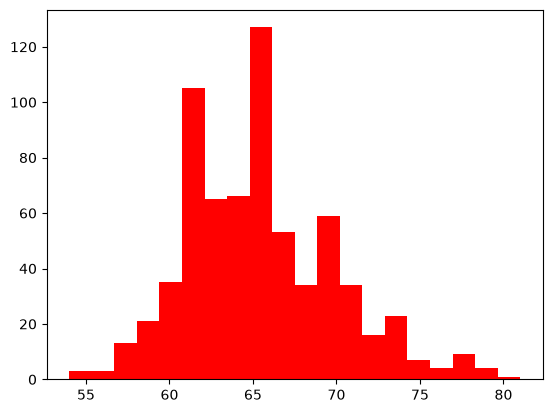

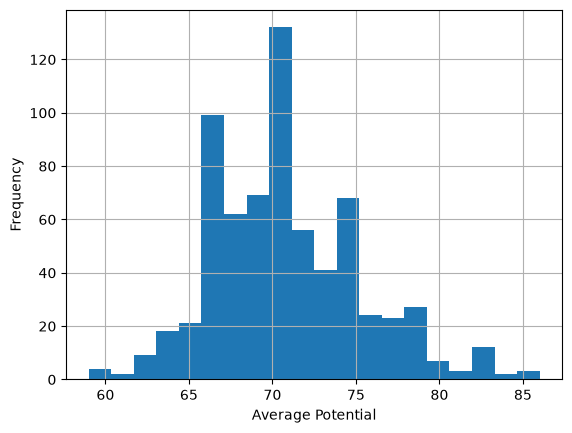

In [87]:
# w/ pyspark_dist_explroe

fifa21.createOrReplaceTempView("fifa_view")

fifa_21_avg_ovr = spark.sql(
    """
    SELECT Club, ROUND(AVG(Overall), 0) as avg_ovr
    FROM fifa_view
    GROUP BY Club
    ORDER BY avg_ovr DESC
    """
)
import matplotlib.pyplot as plt
from pyspark_dist_explore import hist

avg_ovr_df = fifa_21_avg_ovr.select('avg_ovr')

fig, ax = plt.subplots()
hist(ax, avg_ovr_df, bins = 20, color = ['red'])
plt.show()

# w/ toPandas()

fifa_21_avg_pot = spark.sql(
    """
    SELECT Club, ROUND(AVG(Potential), 0) as avg_pot
    FROM fifa_view
    GROUP BY Club
    ORDER BY avg_pot DESC
    """
)

fifa_21_avg_pot_pd = fifa_21_avg_pot.toPandas()

fifa_21_avg_pot_pd['avg_pot'].hist(bins=20)
plt.xlabel('Average Potential')
plt.ylabel('Frequency')
plt.show()


# HandySpark

# from handyspark import *

# fifa_21_avg_value = spark.sql(
#     """
#     SELECT Club, ROUND(AVG(Value), 0) as avg_value
#     FROM fifa_view
#     GROUP BY Club
#     ORDER BY avg_value DESC
#     """
# )

# # forces Spark to treat it as a plain DataFrame
# fifa_21_avg_value.createOrReplaceTempView("fifa_avg_view")
# fifa_plain = spark.sql("SELECT * FROM fifa_avg_view")

# fifa_hdf = fifa_plain.toHandy()

# fifa_hdf.cols['avg_value'].hist()
# plt.show()


In [89]:
file_path = "Fifa2021_dataset.csv"

In [90]:
# Load the Dataframe
fifa_df = spark.read.csv(file_path, header=True, inferSchema=True)

# Check the schema of columns
fifa_df.printSchema()

# Show the first 10 observations
fifa_df.show(10)

# Print the total number of rows
print("There are {} rows in the fifa_df DataFrame".format(fifa_df.count()))

root
 |-- Name: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Photo: string (nullable = true)
 |-- Nationality: string (nullable = true)
 |-- Flag: string (nullable = true)
 |-- Overall: integer (nullable = true)
 |-- Potential: integer (nullable = true)
 |-- Club: string (nullable = true)
 |-- Club Logo: string (nullable = true)
 |-- Value: integer (nullable = true)
 |-- Wage: integer (nullable = true)
 |-- Special: string (nullable = true)
 |-- Acceleration: integer (nullable = true)
 |-- Aggression: integer (nullable = true)
 |-- Agility: integer (nullable = true)
 |-- Balance: integer (nullable = true)
 |-- Ball control: integer (nullable = true)
 |-- Composure: integer (nullable = true)
 |-- Crossing: integer (nullable = true)
 |-- Curve: integer (nullable = true)
 |-- Dribbling: integer (nullable = true)
 |-- Finishing: integer (nullable = true)
 |-- Free kick accuracy: integer (nullable = true)
 |-- GK diving: integer (nullable = true)
 |-- GK handling: integ

In [91]:
# Create a temporary view of fifa_df
fifa_df.createOrReplaceTempView('fifa_df_table')

# Construct a "query" to extract the "Age" column from Germany players in fifa_df_table.
query = '''SELECT Age FROM fifa_df_table WHERE Nationality == "Germany"'''

# Apply the SQL "query"
fifa_df_germany_age = spark.sql(query)

# Generate basic statistics
fifa_df_germany_age.describe().show()

+-------+-----------------+
|summary|              Age|
+-------+-----------------+
|  count|             1189|
|   mean|24.68124474348192|
| stddev|4.263835842572636|
|    min|               17|
|    max|               41|
+-------+-----------------+



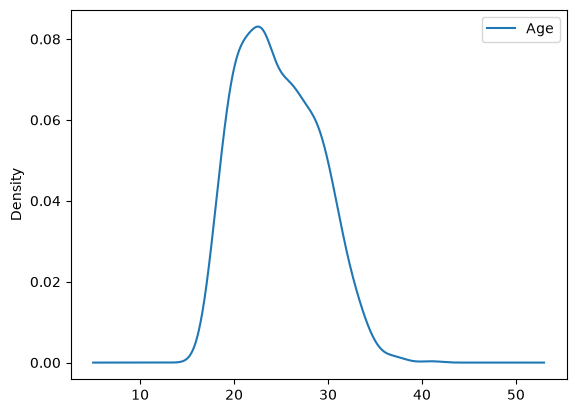

In [92]:
# Convert fifa_df to fifa_df_germany_age_pandas DataFrame
fifa_df_germany_age_pandas = fifa_df_germany_age.toPandas()

# Plot the 'Age' density of Germany Players
fifa_df_germany_age_pandas.plot(kind='density')
plt.show()

# IV

## Overview of PySpark MLlib


- PySpark MLlib: Spark's **built-in library for scalable machine learning**
- Focus of this chapter: the three C's — **Collaborative filtering, Classification, Clustering**

### What is PySpark MLlib?

Quick definition to anchor things:

> Machine learning — algorithms that can **learn from data**.

PySpark MLlib is Spark's ML library. Its goal: make practical machine learning **scalable and easy**.

At a high level, MLlib provides three families of tools:

- **ML algorithms** — collaborative filtering, classification, clustering, regression
- **Featurisation** — feature extraction, transformation, dimensionality reduction, selection
- **Pipelines** — constructing, evaluating and tuning ML pipelines

### Why PySpark MLlib (and not Scikit-learn)?

Scikit-learn is well known and genuinely easy to use — so what gap does MLlib fill?

| | **Scikit-learn** | **PySpark MLlib** |
|---|---|---|
| **Data size** | Small to medium — must fit on one machine | Large — distributed across cluster nodes |
| **Execution** | Single machine | Parallel across nodes |
| **Language support** | Python only | Python, Scala, Java, R |
| **Pipeline API** | Yes, but single-machine | High-level, distributed |

Key point: MLlib only contains algorithms whose operations **can be parallelised across nodes**. If a classical algorithm doesn't parallelise well, it simply isn't in MLlib.

MLlib is also well-suited to **iterative algorithms** — important because many ML algorithms (gradient descent, ALS, k-means) iterate until convergence, and Spark's in-memory execution model makes iteration efficient.

### Algorithms available in MLlib

Broad coverage across the usual ML categories:

**Classification & regression**

- Linear SVMs
- Logistic regression
- Decision trees
- Random forests
- Gradient-boosted trees
- Naive Bayes
- Linear least squares
- Lasso regression
- Ridge regression
- Isotonic regression

Supports **binary classification**, **multiclass classification** and **regression**.

**Collaborative filtering** (recommender systems)

- **Alternating Least Squares (ALS)** — the workhorse algorithm MLlib uses for recommendations

**Clustering**

- k-means
- Gaussian mixture
- Power iteration clustering
- Bisecting k-means
- Streaming k-means

### The three C's

The chapter narrows down to three key areas:

- **Collaborative filtering** — produces recommendations based on past behaviour, preferences or similarities to known users/items
- **Classification** — identifies which of a set of categories a new observation belongs to
- **Clustering** — groups data into clusters based on similar characteristics

Mnemonic to lock in: **Recommend → Label → Group**.

### Importing MLlib classes

Each algorithm lives in a dedicated submodule under `pyspark.mllib`.

**Collaborative filtering → `pyspark.mllib.recommendation`**

```python
from pyspark.mllib.recommendation import ALS
```

**Classification → `pyspark.mllib.classification`**

```python
from pyspark.mllib.classification import LogisticRegressionWithLBFGS
```

**Clustering → `pyspark.mllib.clustering`**

```python
from pyspark.mllib.clustering import KMeans
```

Important to remember: the submodule name mirrors the ML task — `recommendation`, `classification`, `clustering`. Makes imports easy to guess without looking them up.

### Key takeaways — cheat sheet

**Three C's → three submodules:**

| Task | Submodule | Main class covered |
|---|---|---|
| Collaborative filtering | `pyspark.mllib.recommendation` | `ALS` |
| Classification | `pyspark.mllib.classification` | `LogisticRegressionWithLBFGS` |
| Clustering | `pyspark.mllib.clustering` | `KMeans` |

**Things to lock in:**

- MLlib = **Spark's own ML library**, built for scalability
- Only includes algorithms that **parallelise well across a cluster**
- Pick **MLlib over Scikit-learn** when the dataset is too big for a single machine, when a distributed pipeline is needed, or when a non-Python language is in play
- Iterative algorithms benefit from Spark's **in-memory execution** — a big reason ALS, logistic regression and k-means run efficiently on it
- Submodule naming is predictable: `pyspark.mllib.<task>`
- Three C's: **Collaborative filtering, Classification, Clustering** — the focus from here on

In [ ]:
# Import pyspark.mllib recommendation submodule and Alternating Least Squares class.
from pyspark.mllib.recommendation import ALS

# Import pyspark.mllib classification submodule and Logistic Regression with LBFGS class.
from pyspark.mllib.classification import LogisticRegressionWithLBFGS

# Import pyspark.mllib clustering submodule and kmeans class.
from pyspark.mllib.clustering import KMeans

## Introduction to Collaborative Filtering


- First of the **three C's** → **Collaborative filtering**
- Core use case: **recommender systems** in Spark
- Covers: the `Rating` class, splitting data with `randomSplit`, training with **ALS**, prediction with `predictAll`, evaluation with **MSE**

### What is collaborative filtering?

**Collaborative filtering** = making automatic predictions about a user's interests by collecting **preferences or taste information from many users**.

One of the most widely used algorithms in recommender systems (Netflix, Amazon, Spotify, etc. all lean on variants of it).

**Two approaches:**

| Approach | How it works |
|---|---|
| **User-User** | Finds users *similar to* the target user and uses their ratings to recommend |
| **Item-Item** | Finds items *similar to* those the target user already likes/rated |

Important intuition: there's no explicit "features of a user" or "features of a movie" — the model learns latent features purely from the ratings matrix.

### The `Rating` class

Lives in `pyspark.mllib.recommendation`. It's a simple **wrapper around the tuple `(user, product, rating)`** — ALS expects data in exactly this shape.

```python
from pyspark.mllib.recommendation import Rating

# Create a single Rating
r = Rating(user=1, product=2, rating=5.0)

# Index access works like a tuple
print(r[0])   # 1    → userId
print(r[1])   # 2    → productId
print(r[2])   # 5.0  → rating
```

Useful for parsing an RDD of raw tuples into typed Rating objects before training.

### Splitting data with `randomSplit()`

A training / testing split is fundamental: **train** on one portion, **evaluate** on the other to check generalisation. Typically a larger slice for training (e.g. 70–80%) and a smaller one for testing.

PySpark's `randomSplit` takes a list of **weights** and returns that many RDDs, randomly partitioned according to the weights.

```python
# RDD of numbers 1 to 10
data = sc.parallelize(range(1, 11))

# 60/40 split
training, test = data.randomSplit([0.6, 0.4])

print(training.collect())  # e.g. [1, 3, 4, 6, 8, 10]  — 6 elements
print(test.collect())      # e.g. [2, 5, 7, 9]          — 4 elements
```

Important point: the split is **random** — exact counts vary between runs. Weights don't have to sum to 1, but it's convention to make them do so for readability.

### Alternating Least Squares (ALS)

The ALS algorithm in `spark.mllib` finds products a user might like based on past ratings/purchases. It works by **factorising the ratings matrix** into two lower-dimensional matrices (one for users, one for items) and alternately solving for each.

`ALS.train()` expects:

- An **RDD of `Rating` objects** (or `(userId, itemId, rating)` tuples)
- `rank` → number of **latent features** to learn
- `iterations` → number of iterations of least squares to run

```python
from pyspark.mllib.recommendation import ALS, Rating

# Create an RDD of Rating objects
ratings_data = [
    Rating(1, 1, 1.0),
    Rating(1, 2, 2.0),
    Rating(2, 1, 2.0),
    Rating(2, 2, 3.0),
    Rating(3, 1, 3.0),
    Rating(3, 2, 4.0),
]
ratings_RDD = sc.parallelize(ratings_data)

print(ratings_RDD.collect())

# Train the ALS model
model = ALS.train(ratings_RDD, rank=10, iterations=10)
```

Rules of thumb:

- **`rank`** too low → underfits (can't capture taste nuance)
- **`rank`** too high → overfits and bloats memory
- **`iterations`** typically 5–20; more

In [100]:
file_path = "ratings.csv"

In [101]:
from pyspark.mllib.recommendation import Rating

# Load the `ratings.csv` dataset into an RDD.
data = sc.textFile(file_path)

# Split the RDD using `,` as a delimiter.
ratings = data.map(lambda l: l.split(','))

# For each line of the RDD, using `Rating()` class create a tuple of `userID, productID, rating`.
ratings_final = ratings.map(lambda line: Rating(int(line[0]), int(line[1]), float(line[2])))

# Randomly split the data into training data and test data (0.8 and 0.2).
training_data, test_data = ratings_final.randomSplit([0.8, 0.2])

In [102]:
# Create the ALS model on the training data
model = ALS.train(training_data, rank=10, iterations=10)

# Drop the ratings column 
testdata_no_rating = test_data.map(lambda p: (p[0], p[1]))

# Predict the model  
predictions = model.predictAll(testdata_no_rating)

# Return the first 2 rows of the RDD
predictions.take(2)

[Rating(user=529, product=3456, rating=2.0235483517233313),
 Rating(user=468, product=6156, rating=2.4081354839099514)]

In [103]:
# Prepare ratings data
rates = ratings_final.map(lambda r: ((r[0], r[1]), r[2]))

# Prepare predictions data
preds = predictions.map(lambda r: ((r[0], r[1]), r[2]))

# Join the ratings data with predictions data
rates_and_preds = rates.join(preds)

# Calculate and print MSE
MSE = rates_and_preds.map(lambda r: (r[1][0] - r[1][1])**2).mean()
print("Mean Squared Error of the model for the test data = {:.2f}".format(MSE))

Mean Squared Error of the model for the test data = 1.35


## Classification


- Second of the three C's → **Classification**
- A **supervised learning** technique: learn from labelled examples, then label new ones
- Covers: binary vs multiclass, logistic regression, Vectors (dense/sparse), `LabeledPoint`, `HashingTF`, `LogisticRegressionWithLBFGS`

### Classification in PySpark MLlib

**Classification** = identifying which category an item belongs to — e.g. "is this email spam or not?".

How it works:

- Starts with data of **known labels** and **pre-determined features**
- Learns a mapping from features → label
- Applies that mapping to new, unseen records

That reliance on labelled training data is exactly what makes it **supervised learning**.

**Two types:**

| Type | Classes | Example |
|---|---|---|
| **Binary** | Exactly 2 | Is this tumour malignant? |
| **Multiclass** | More than 2 | What category is this news article? |

**PySpark MLlib supports:**

- **Binary**: linear SVMs, logistic regression, decision trees, random forests, gradient-boosted trees, naive Bayes
- **Multiclass**: logistic regression, decision trees, random forests, naive Bayes

### Logistic regression — introduction

The most popular supervised classification method. Despite the "regression" in its name, it is a **classification** algorithm.

Core idea:

- Measures the relationship between a **label** (Y-axis) and **features** (X-axis) via a **logistic function** (the characteristic S-curve)
- Output is a **probability** between 0 and 1
- By convention: probability > 0.5 → class **1**, otherwise → class **0**

Important to lock in: the raw output is *probability*; the 0.5 threshold converts it into a hard class label.

### Vectors — dense vs sparse

MLlib has its own `Vector` type, distinct from Python lists or NumPy arrays. Two flavours:

- **Dense** — stores *every* entry in an array of doubles. Good when most values are non-zero.
- **Sparse** — stores only the **non-zero** entries along with their indices. Good when the vector is mostly zeros (e.g. text data).

```python
from pyspark.mllib.linalg import Vectors

# Dense: all three entries stored
dv = Vectors.dense([1.0, 2.0, 3.0])

# Sparse: size 4, non-zero entries at index 1 (= 1.0) and index 3 (= 5.5)
sv = Vectors.sparse(4, {1: 1.0, 3: 5.5})
# Equivalent positional form:
# sv = Vectors.sparse(4, [1, 3], [1.0, 5.5])

print(dv)   # [1.0,2.0,3.0]
print(sv)   # (4,[1,3],[1.0,5.5])
```

Key point: sparse vectors matter a lot for **text features** — a 10,000-term vocabulary with one sentence of input might only touch 5 indices. Storing 9,995 zeros would be ridiculous.

### `LabeledPoint`

A `LabeledPoint` is a wrapper around a **(label, feature vector)** pair. It's what the classification trainers in MLlib expect.

- **Label** → a floating-point value. For binary classification: **1.0** (positive) or **0.0** (negative). For multiclass: 0.0, 1.0, 2.0, …
- **Feature vector** → a dense or sparse `Vector`

```python
from pyspark.mllib.regression import LabeledPoint

# Positive example
positive = LabeledPoint(1.0, [1.0, 0.0, 3.0])

# Negative example
negative = LabeledPoint(0.0, [2.0, 1.0, 1.0])

print(positive.label, positive.features)   # 1.0 [1.0,0.0,3.0]
print(negative.label, negative.features)   # 0.0 [2.0,1.0,1.0]
```

### `HashingTF` — turning text into features

`HashingTF` computes a **term-frequency vector** of a fixed size from a document. Essential for text classification tasks (e.g. spam detection).

How it works:

1. Hashes each word into one of `numFeatures` buckets
2. Counts occurrences per bucket
3. Returns a **sparse vector** of size `numFeatures`

```python
from pyspark.mllib.feature import HashingTF

sentence = "hello hello world"
words = sentence.split()   # ['hello', 'hello', 'world']

tf = HashingTF(10000)
tf_vector = tf.transform(words)

print(tf_vector)
# (10000,[<idx_hello>,<idx_world>],[2.0,1.0])
```

Key point: the output is a **sparse vector** — size 10,000, but only the buckets corresponding to words actually present are populated.

Trade-offs:

- Bigger `numFeatures` → fewer hash collisions, more memory
- Hash collisions mean two distinct words can land in the same bucket — usually harmless for large enough `numFeatures`

### Logistic regression with `LogisticRegressionWithLBFGS`

**LBFGS** (Limited-memory BFGS) is the popular optimiser used to fit logistic regression in MLlib. Faster convergence than plain gradient descent on most problems.

Minimum requirement: an **RDD of `LabeledPoint`** objects.

```python
from pyspark.mllib.regression import LabeledPoint
from pyspark.mllib.classification import LogisticRegressionWithLBFGS

# Build training data — list of LabeledPoints → RDD
data = [
    LabeledPoint(0.0, [0.0, 1.0]),
    LabeledPoint(1.0, [1.0, 0.0]),
    LabeledPoint(0.0, [0.2, 0.9]),
    LabeledPoint(1.0, [0.9, 0.1]),
]
training_RDD = sc.parallelize(data)

# Train the model
model = LogisticRegressionWithLBFGS.train(training_RDD)

# Predict on a new feature vector
print(model.predict([0.8, 0.2]))   # → 1
print(model.predict([0.1, 0.9]))   # → 0
```

Important to remember: `predict()` returns the **hard class label** (0 or 1), not the probability. For the probability, the `LogisticRegressionModel` exposes additional methods — but the default `predict` jumps straight to the 0.5-threshold decision.

### Key takeaways — cheat sheet

**End-to-end text classification workflow:**

```python
from pyspark.mllib.regression import LabeledPoint
from pyspark.mllib.feature import HashingTF
from pyspark.mllib.classification import LogisticRegressionWithLBFGS

tf = HashingTF(10000)

# 1. Turn each (label, raw_text) into a LabeledPoint
def to_labeled_point(label, text):
    return LabeledPoint(label, tf.transform(text.split()))

training_RDD = sc.parallelize([
    to_labeled_point(1.0, "buy now cheap meds"),
    to_labeled_point(0.0, "meeting at ten tomorrow"),
    # ...
])

# 2. Train
model = LogisticRegressionWithLBFGS.train(training_RDD)

# 3. Predict on new text
new_features = tf.transform("cheap offer now".split())
print(model.predict(new_features))
```

**Things to lock in:**

- Classification is **supervised** — needs labelled training data
- **Binary** (2 classes) vs **multiclass** (more than 2)
- Logistic regression → outputs a **probability**, thresholded at 0.5
- `Vectors.dense(...)` vs `Vectors.sparse(size, {idx: val, ...})` — pick sparse when mostly zeros
- `LabeledPoint(label, features)` is the required input shape for MLlib classifiers
- `HashingTF(numFeatures)` + `.transform(word_list)` → sparse TF vector; standard tool for text features
- `LogisticRegressionWithLBFGS.train(rdd_of_labeled_points)` → model whose `.predict()` returns a class label
- Watch the spelling: the PySpark class is **`LabeledPoint`** (American spelling in the API, even though notes say *labelled*)

In [104]:
file_path_spam = 'spam.txt'
file_path_non_spam = 'ham.txt'

In [106]:
# Load the datasets into RDDs
spam_rdd = sc.textFile(file_path_spam)
non_spam_rdd = sc.textFile(file_path_non_spam)

# Split the email messages into words
spam_words = spam_rdd.flatMap(lambda email: email.split(' '))
non_spam_words = non_spam_rdd.flatMap(lambda email: email.split(' '))

# Print the first element in the split RDD
print("The first element in spam_words is", spam_words.first())
print("The first element in non_spam_words is", non_spam_words.first())

The first element in spam_words is You
The first element in non_spam_words is Rofl.


In [ ]:
from pyspark.mllib.feature import HashingTF

# Create a HashingTF instance with 200 features
tf = HashingTF(numFeatures=200)

# Map each word to one feature
spam_features = tf.transform(spam_words)
non_spam_features = tf.transform(non_spam_words)

# Label the features: 1 for spam, 0 for non-spam
spam_samples = spam_features.map(lambda features: LabeledPoint(1, features))
non_spam_samples = non_spam_features.map(lambda features: LabeledPoint(0, features))

# Combine the two datasets
samples = spam_samples.union(non_spam_samples)

In [115]:
from pyspark.mllib.regression import LabeledPoint
from pyspark.mllib.classification import LogisticRegressionWithLBFGS

# Split the data into training and testing
train_samples, test_samples = samples.randomSplit([0.8, 0.2])

# Train the model
model = LogisticRegressionWithLBFGS.train(train_samples)

# Create a prediction label from the test data
predictions = model.predict(test_samples.map(lambda x: x.features))

# Combine original labels with the predicted labels
labels_and_preds = test_samples.map(lambda x: x.label).zip(predictions)

# Check the accuracy of the model on the test data
accuracy = labels_and_preds.filter(lambda x: x[0] == x[1]).count() / float(test_samples.count())
print("Model accuracy : {:.2f}".format(accuracy))

26/11/15 17:48:16 ERROR PythonRunner: Python worker exited unexpectedly (crashed)
org.apache.spark.api.python.PythonException: Traceback (most recent call last):
  File "/home/mothma/dc-pyspark/.venv/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/worker.py", line 1225, in main
    eval_type = read_int(infile)
                ^^^^^^^^^^^^^^^^
  File "/home/mothma/dc-pyspark/.venv/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/serializers.py", line 596, in read_int
    raise EOFError
EOFError

	at org.apache.spark.api.python.BasePythonRunner$ReaderIterator.handlePythonException(PythonRunner.scala:572)
	at org.apache.spark.api.python.PythonRunner$$anon$3.read(PythonRunner.scala:784)
	at org.apache.spark.api.python.PythonRunner$$anon$3.read(PythonRunner.scala:766)
	at org.apache.spark.api.python.BasePythonRunner$ReaderIterator.hasNext(PythonRunner.scala:525)
	at org.apache.spark.InterruptibleIterator.hasNext(InterruptibleIterator.scala:37)
	at scal

Py4JJavaError: An error occurred while calling z:org.apache.spark.api.python.PythonRDD.runJob.
: org.apache.spark.SparkException: Job aborted due to stage failure: Task 0 in stage 505.0 failed 1 times, most recent failure: Lost task 0.0 in stage 505.0 (TID 667) (10.255.255.254 executor driver): org.apache.spark.api.python.PythonException: Traceback (most recent call last):
  File "/home/mothma/dc-pyspark/.venv/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/worker.py", line 1247, in main
    process()
  File "/home/mothma/dc-pyspark/.venv/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/worker.py", line 1239, in process
    serializer.dump_stream(out_iter, outfile)
  File "/home/mothma/dc-pyspark/.venv/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/serializers.py", line 274, in dump_stream
    vs = list(itertools.islice(iterator, batch))
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/mothma/dc-pyspark/.venv/lib

## Introduction to Clustering


- Third and final C → **Clustering**
- An **unsupervised** learning method — groups **unlabelled** data into clusters of similar items
- Focus: **K-means clustering**, PySpark MLlib's most popular clustering algorithm

### What is clustering?

**Clustering** = the unsupervised task of grouping objects into clusters of **high similarity**, with **no labels** given up front.

Contrast with what came before:

| | **Labels needed?** | **Family** |
|---|---|---|
| Collaborative filtering | Ratings (implicit labels) | Supervised-ish |
| Classification | Yes | Supervised |
| **Clustering** | **No** | **Unsupervised** |

Clustering is how sense gets made of **unlabelled** data — customer segmentation, anomaly detection, document grouping, etc.

**Clustering methods available in PySpark MLlib:**

- K-means clustering
- Gaussian mixture clustering
- Power iteration clustering (PIC)
- Bisecting k-means clustering
- Streaming k-means clustering

Focus here: **K-means** — simple and widely used.

### K-means clustering

Takes `n` data points and groups them into `k` clusters (where `k` is specified **in advance**).

Mechanics (roughly):

1. Start with `k` randomly placed cluster centres (centroids)
2. Assign each point to its nearest centroid
3. Move each centroid to the mean position of its assigned points
4. Repeat until assignments stop changing (or max iterations hit)

**Minimum requirements:**

- Data must be **numerical features**
- Target number of clusters **`k`** must be specified up front

Important to lock in: K-means doesn't *discover* `k` for us — it clusters into *whatever* `k` is chosen. Picking `k` is the main judgement call.

### Loading data for K-means

Step one: get numerical data into an RDD and parse it.

```python
# Load a CSV into an RDD (one line of text per element)
clusterRDD = sc.textFile("5000_points.txt")

# Parse each line on comma, then cast to int
rdd_split = clusterRDD.map(lambda x: x.split(","))
rdd_split_int = rdd_split.map(lambda x: [int(x[0]), int(x[1])])

# Peek at the first 5 rows
print(rdd_split_int.take(5))
# [[664159, 550946], [665845, 557965], ...]
```

Two-column dataset → two features per point. Each inner list is one data point.

### Training a K-means model

Import `KMeans`, then call `.train()` with the RDD, the number of clusters `k`, and a maximum number of iterations.

```python
from pyspark.mllib.clustering import KMeans

# Train — k=2 clusters, up to 10 iterations
model = KMeans.train(rdd_split_int, k=2, maxIterations=10)

# Access the cluster centroids
print(model.clusterCenters)
# [array([ 350000.5, 410000.7]), array([  800000.2, 760000.3])]
```

Key points:

- Returns a **`KMeansModel`**
- `.clusterCenters` → list of centroid coordinate arrays (one per cluster)
- `maxIterations` caps the loop — K-means usually converges well before hitting the cap, but it's a safety net

### Evaluating the model — Within Set Sum of Squared Errors (WSSSE)

Standard metric for K-means: for every point, measure its distance to its assigned centroid; square it; sum across all points. Smaller → tighter, better-defined clusters.

Important to remember: PySpark's `KMeansModel` **doesn't include a built-in method** for this — the error function has to be written by hand.

```python
from math import sqrt

# Error function: distance from a point to its nearest cluster centre
def error(point):
    center = model.centers[model.predict(point)]
    return sqrt(sum([x ** 2 for x in (point - center)]))

# Apply across all points and sum
WSSSE = rdd_split_int.map(lambda point: error(point)).reduce(lambda x, y: x + y)

print("Within Set Sum of Squared Error = " + str(WSSSE))
# Within Set Sum of Squared Error = 77.96
```

Elbow method hint: plot WSSSE for a range of `k` values — the "elbow" where improvement flattens off is a good choice for `k`.

### Visualising K-means clusters

Highly recommended step — a visual overlay of points + centroids immediately shows whether the clustering looks sensible.

Plotting libraries don't work directly on RDDs or Spark DataFrames, so the usual move is:

1. Convert the RDD → Spark DataFrame → pandas DataFrame
2. Convert the cluster centres → pandas DataFrame  
3. Plot with matplotlib

```python
import matplotlib.pyplot as plt
import pandas as pd

# 1. Convert data RDD → Spark DF → pandas DF
rdd_split_int_df = spark.createDataFrame(rdd_split_int, schema=["col1", "col2"])
rdd_split_int_df_pandas = rdd_split_int_df.toPandas()

# 2. Convert cluster centres → pandas DF
cluster_centers_pandas = pd.DataFrame(
    model.clusterCenters,
    columns=["col1", "col2"]
)

# 3. Scatter plot + overlay of cluster centres
fig, ax = plt.subplots()
ax.scatter(
    rdd_split_int_df_pandas["col1"],
    rdd_split_int_df_pandas["col2"],
    s=10,
)
ax.scatter(
    cluster_centers_pandas["col1"],
    cluster_centers_pandas["col2"],
    color="red",
    marker="x",
    s=200,
)
plt.show()
```

The centroids show up as coloured "x" markers over the point cloud — if they sit roughly in the middle of each visible group, the clustering looks reasonable.

### Key takeaways — cheat sheet

**End-to-end K-means workflow:**

```python
from pyspark.mllib.clustering import KMeans
from math import sqrt

# 1. Load + parse numerical data
rdd = sc.textFile("data.csv") \
        .map(lambda x: x.split(",")) \
        .map(lambda x: [int(x[0]), int(x[1])])

# 2. Train
model = KMeans.train(rdd, k=3, maxIterations=10)

# 3. Inspect centroids
print(model.clusterCenters)

# 4. Evaluate — WSSSE (hand-rolled)
def error(point):
    center = model.centers[model.predict(point)]
    return sqrt(sum((point - center) ** 2))

WSSSE = rdd.map(error).reduce(lambda x, y: x + y)

# 5. Visualise (RDD → Spark DF → pandas → matplotlib)
```

**Things to lock in:**

- **Unsupervised** → no labels in the training data
- **`k` is chosen ahead of time** — K-means doesn't discover it
- All features must be **numerical**
- `KMeans.train(rdd, k=..., maxIterations=...)` → `KMeansModel`
- `.clusterCenters` returns centroid coordinates; `.predict(point)` returns the cluster index for a point
- **WSSSE** is the standard metric — lower = tighter clusters; must be **written manually** in PySpark
- Elbow method on WSSSE across a range of `k` values is the usual way to pick `k`
- For visualisation: RDD → Spark DataFrame → pandas → matplotlib; overlay centroids as "x" markers to sanity-check the clustering

In [116]:
file_path = "5000_points.txt"

In [117]:
from pyspark.mllib.clustering import KMeans

# Load the dataset into an RDD
clusterRDD = sc.textFile(file_path)

# Split the RDD based on tab
rdd_split = clusterRDD.map(lambda x: x.split('\t'))

# Transform the split RDD by creating a list of integers
rdd_split_int = rdd_split.map(lambda x: [int(x[0]), int(x[1])])

# Count the number of rows in RDD 
print("There are {} rows in the rdd_split_int dataset".format(rdd_split_int.count()))

There are 5000 rows in the rdd_split_int dataset


In [119]:
# Train the model with clusters from 13 to 16 and compute WSSSE
for clst in range(13, 17):
    model = KMeans.train(rdd_split_int, clst, seed=1)
    WSSSE = rdd_split_int.map(lambda point: error(point)).reduce(lambda x, y: x + y)
    print("The cluster {} has Within Set Sum of Squared Error {}".format(clst, WSSSE))

# Train the model again with the best k
model = KMeans.train(rdd_split_int, k=16, seed=1)

# Get cluster centers
cluster_centers = model.clusterCenters

26/11/15 17:57:49 ERROR Executor: Exception in task 0.0 in stage 552.0 (TID 760)
org.apache.spark.api.python.PythonException: Traceback (most recent call last):
  File "/home/mothma/dc-pyspark/.venv/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/worker.py", line 1247, in main
    process()
  File "/home/mothma/dc-pyspark/.venv/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/worker.py", line 1239, in process
    serializer.dump_stream(out_iter, outfile)
  File "/home/mothma/dc-pyspark/.venv/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/serializers.py", line 274, in dump_stream
    vs = list(itertools.islice(iterator, batch))
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/mothma/dc-pyspark/.venv/lib/python3.12/site-packages/pyspark/rdd.py", line 1919, in func
    initial = next(iterator)
              ^^^^^^^^^^^^^^
  File "/home/mothma/dc-pyspark/.venv/lib/python3.12/site-packages/pyspark/python/lib/pyspark.z

Py4JJavaError: An error occurred while calling z:org.apache.spark.api.python.PythonRDD.collectAndServe.
: org.apache.spark.SparkException: Job aborted due to stage failure: Task 0 in stage 552.0 failed 1 times, most recent failure: Lost task 0.0 in stage 552.0 (TID 760) (10.255.255.254 executor driver): org.apache.spark.api.python.PythonException: Traceback (most recent call last):
  File "/home/mothma/dc-pyspark/.venv/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/worker.py", line 1247, in main
    process()
  File "/home/mothma/dc-pyspark/.venv/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/worker.py", line 1239, in process
    serializer.dump_stream(out_iter, outfile)
  File "/home/mothma/dc-pyspark/.venv/lib/python3.12/site-packages/pyspark/python/lib/pyspark.zip/pyspark/serializers.py", line 274, in dump_stream
    vs = list(itertools.islice(iterator, batch))
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/mothma/dc-pyspark/

In [ ]:
# Convert rdd_split_int RDD into Spark DataFrame and then to Pandas DataFrame
rdd_split_int_df_pandas = spark.createDataFrame(rdd_split_int, schema=["col1", "col2"]).toPandas()

# Convert cluster_centers to a pandas DataFrame
cluster_centers_pandas = pd.DataFrame(cluster_centers, columns=["col1", "col2"])

# Create an overlaid scatter plot of clusters and centroids
plt.scatter(rdd_split_int_df_pandas["col1"], rdd_split_int_df_pandas["col2"])
plt.scatter(cluster_centers_pandas["col1"], cluster_centers_pandas["col2"], color="red", marker="x")
plt.show()